# Ski Resort Snowpack and Warming Sensitivity — Reproducible Analysis

**Final research workflow | 91 western U.S. ski resorts | Winters 2004–2023**

This notebook consolidates the final recursive XGBoost analysis from the original 204-cell exploratory notebook. It documents the data assembly, temporal holdout, daily snow-depth prediction, snow-season definition, historical warming perturbations, resort-cluster bootstrap, spatial vulnerability, validation, and thesis outputs.

**Scope:** Natural snow depth, *not* resort operating days, revenue, snowmaking-adjusted snow cover, or future climate projections. Temperature increases are applied uniformly to historical weather; precipitation is held fixed.

**Reproduction:** Run cells in order from the project root (`ski_thesis_clean`). The notebook expects existing input CSVs in `inputs/ski_resorts/`; it does not repeat Google Earth Engine exports or early experimental models. The warming simulations can take substantial time. Original notebook retained separately as the research archive.

**Environment:** Python, numpy, pandas, matplotlib, scikit-learn, xgboost, geopandas, shapely, and a network connection for Census boundaries (or cached boundaries).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

PROJECT_ROOT = Path.cwd()
INPUT_DIR = PROJECT_ROOT / "inputs" / "ski_resorts"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
FIG_DIR = OUTPUT_DIR / "thesis_figures"
TABLE_DIR = OUTPUT_DIR / "thesis_tables"
for directory in [OUTPUT_DIR, FIG_DIR, TABLE_DIR]:
    directory.mkdir(parents=True, exist_ok=True)
assert INPUT_DIR.is_dir(), f"Expected input directory: {INPUT_DIR}"
print("Project root:", PROJECT_ROOT)


Project root: /Users/evabenson/Files/thesis/ski_thesis_clean


## 1. Input data and construction

Input data were exported in the original project using SNODAS snow-depth observations, Daymet meteorological data, and SRTM terrain characteristics at resort base-area locations. The extraction code and original experiments remain in the archival notebook. This section assembles the already-exported CSVs. **Check input file versions and coverage before reproducing results.**

### Locate annual SNODAS, Daymet, and terrain files

*Adapted from original notebook cell 134; retained for methodological traceability.*

In [2]:

from pathlib import Path
import pandas as pd
import re

folder = Path("inputs/ski_resorts")

# Match annual files only, excluding combined datasets
daymet_files = sorted(
    f for f in folder.glob("resort_daymet_base_daily_*.csv")
    if re.fullmatch(
        r"resort_daymet_base_daily_\d{4}\.csv",
        f.name
    )
)

snodas_files = sorted(
    f for f in folder.glob("resort_snodas_base_daily_*.csv")
    if re.fullmatch(
        r"resort_snodas_base_daily_\d{4}\.csv",
        f.name
    )
)

terrain_file = folder / "resort_base_terrain_91.csv"

print("Daymet annual files:", len(daymet_files))
print("SNODAS annual files:", len(snodas_files))
print("Terrain file exists:", terrain_file.exists())

print("\nDaymet years:")
print([int(f.stem[-4:]) for f in daymet_files])

print("\nSNODAS years:")
print([int(f.stem[-4:]) for f in snodas_files])

if terrain_file.exists():
    terrain_df = pd.read_csv(terrain_file)
    print("\nTerrain dataset shape:", terrain_df.shape)
    print("Terrain columns:", terrain_df.columns.tolist())
    display(terrain_df.head(3))


Daymet annual files: 20
SNODAS annual files: 20
Terrain file exists: True

Daymet years:
[2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023]

SNODAS years:
[2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023]

Terrain dataset shape: (91, 7)
Terrain columns: ['resort_id', 'resort_name', 'elevation_m', 'slope_deg', 'northness', 'eastness', 'elevation_std_150m']


,resort_id,resort_name,elevation_m,slope_deg,northness,eastness,elevation_std_150m
0,f357cc18ead38a393c55cf27921fe05913dc33e1,Bear Valley,2210.698879,26.849010,0.630880,-0.292672,33.611503
1,9e118f4eb36fb34e987c7a3ddd7f2d976b6a7443,China Peak Mountain Resort,2251.239649,16.546806,0.727741,-0.033769,21.304366
2,162525ff9a2a65810a602b74f338303d1bb9ea38,Dodge Ridge Ski Area,2106.171045,14.888862,0.438877,-0.414893,16.622472


### Merge daily weather, snow depth, and terrain

*Adapted from original notebook cell 135; retained for methodological traceability.*

In [3]:

import pandas as pd

# Load all 20 years
snodas = pd.concat(
    [pd.read_csv(f) for f in snodas_files],
    ignore_index=True
)

daymet = pd.concat(
    [pd.read_csv(f) for f in daymet_files],
    ignore_index=True
)

terrain = pd.read_csv(terrain_file)

# Standardize dates
snodas["date"] = pd.to_datetime(snodas["date"])
daymet["date"] = pd.to_datetime(daymet["date"])

# Check for duplicate keys before merging
for name, df in [("SNODAS", snodas), ("Daymet", daymet)]:
    duplicates = df.duplicated(
        ["resort_id", "date"]
    ).sum()
    print(f"{name} duplicate resort-date rows: {duplicates}")

print(
    "Terrain duplicate resort IDs:",
    terrain.duplicated("resort_id").sum()
)

# Keep the snow depth and weather variables
snodas_clean = snodas[
    ["resort_id", "date", "mean"]
].rename(columns={"mean": "snow_depth_m"})

daymet_clean = daymet[
    [
        "resort_id", "date",
        "tmin", "tmax", "prcp", "srad", "dayl"
    ]
]

terrain_clean = terrain.drop(
    columns=["resort_name"]
)

# Merge using resort ID and date
daily_model = snodas_clean.merge(
    daymet_clean,
    on=["resort_id", "date"],
    how="left",
    validate="one_to_one"
)

daily_model = daily_model.merge(
    terrain_clean,
    on="resort_id",
    how="left",
    validate="many_to_one"
)

# Add winter year
daily_model["winter_year"] = (
    daily_model["date"].dt.year
    + (daily_model["date"].dt.month >= 10).astype(int)
)

daily_model = daily_model.sort_values(
    ["resort_id", "date"]
).reset_index(drop=True)

print("\nMerged dataset shape:", daily_model.shape)
print("Unique resorts:", daily_model["resort_id"].nunique())
print("Winter years:", daily_model["winter_year"].nunique())

print("\nMissing values:")
print(daily_model.isna().sum())

print("\nSnow depth summary (meters):")
display(daily_model["snow_depth_m"].describe().round(3))

print("\nFirst five rows:")
display(daily_model.head())


SNODAS duplicate resort-date rows: 0
Daymet duplicate resort-date rows: 0
Terrain duplicate resort IDs: 0

Merged dataset shape: (496405, 14)
Unique resorts: 91
Winter years: 20

Missing values:
resort_id               0
date                    0
snow_depth_m            0
tmin                  455
tmax                  455
prcp                  455
srad                  455
dayl                  455
elevation_m             0
slope_deg               0
northness               0
eastness                0
elevation_std_150m      0
winter_year             0
dtype: int64

Snow depth summary (meters):


count    496405.000
mean          0.622
std           0.776
min           0.000
25%           0.000
50%           0.345
75%           0.967
max           6.221
Name: snow_depth_m, dtype: float64


First five rows:


,resort_id,date,snow_depth_m,tmin,tmax,prcp,srad,dayl,elevation_m,slope_deg,northness,eastness,elevation_std_150m,winter_year
0,01fc91766cf1ba8156fdc3d233e90205b0dd3001,2003-10-01,0.0,6.806610,18.212203,0.0,350.816621,41548.159980,2160.920862,23.546263,0.077521,0.466006,27.770223,2004
1,01fc91766cf1ba8156fdc3d233e90205b0dd3001,2003-10-02,0.0,4.964859,18.056610,0.0,380.465359,41391.897422,2160.920862,23.546263,0.077521,0.466006,27.770223,2004
2,01fc91766cf1ba8156fdc3d233e90205b0dd3001,2003-10-03,0.0,5.692881,18.306837,0.0,368.080290,41235.955177,2160.920862,23.546263,0.077521,0.466006,27.770223,2004
3,01fc91766cf1ba8156fdc3d233e90205b0dd3001,2003-10-04,0.0,7.422655,17.750339,0.0,318.310560,41080.333245,2160.920862,23.546263,0.077521,0.466006,27.770223,2004
4,01fc91766cf1ba8156fdc3d233e90205b0dd3001,2003-10-05,0.0,6.152768,17.928475,0.0,346.588860,40925.080817,2160.920862,23.546263,0.077521,0.466006,27.770223,2004


### Interpolate isolated missing Daymet weather values

*Adapted from original notebook cell 137; retained for methodological traceability.*

In [4]:

import numpy as np

# Preserve an indicator for missing Daymet dates
daily_model["daymet_missing_original"] = (
    daily_model["tmin"].isna()
)

# Interpolate continuous weather variables within each resort
continuous_vars = ["tmin", "tmax", "srad", "dayl"]

daily_model = daily_model.sort_values(
    ["resort_id", "date"]
).reset_index(drop=True)

for variable in continuous_vars:
    daily_model[variable] = (
        daily_model.groupby("resort_id")[variable]
        .transform(
            lambda s: s.interpolate(
                method="linear",
                limit=1,
                limit_area="inside"
            )
        )
    )

print("Originally missing Daymet rows:",
      daily_model["daymet_missing_original"].sum())

print("\nRemaining missing values:")
print(
    daily_model[
        ["tmin", "tmax", "prcp", "srad", "dayl"]
    ].isna().sum()
)

print("\nInterpolated dates:")
display(
    daily_model.loc[
        daily_model["daymet_missing_original"],
        ["date", "winter_year", "tmin", "tmax", "prcp"]
    ].drop_duplicates("date")
)


Originally missing Daymet rows: 455

Remaining missing values:
tmin      0
tmax      0
prcp    455
srad      0
dayl      0
dtype: int64

Interpolated dates:


,date,winter_year,tmin,tmax,prcp
363,2004-12-31,2005,-5.049915,-1.967797,NaN
1449,2008-12-31,2009,-3.562119,8.555141,NaN
2541,2012-12-31,2013,-10.515932,-1.930085,NaN
3634,2016-12-31,2017,-5.042797,4.480113,NaN
4727,2020-12-31,2021,-6.043220,6.093107,NaN


### Complete precipitation interpolation and save daily panel

*Adapted from original notebook cell 138; retained for methodological traceability.*

In [5]:

from pathlib import Path

# Fill the five missing precipitation dates
# using neighboring daily observations
daily_model["prcp"] = (
    daily_model.groupby("resort_id")["prcp"]
    .transform(
        lambda s: s.interpolate(
            method="linear",
            limit=1,
            limit_area="inside"
        )
    )
)

# Check that all variables are complete
print("Remaining missing values:")
print(daily_model.isna().sum())

print("\nInterpolated precipitation summary (mm/day):")
display(
    daily_model.loc[
        daily_model["daymet_missing_original"],
        "prcp"
    ].describe().round(2)
)

# Confirm uniqueness
assert not daily_model.duplicated(
    ["resort_id", "date"]
).any()

assert daily_model[
    ["snow_depth_m", "tmin", "tmax", "prcp",
     "srad", "dayl", "elevation_m"]
].notna().all().all()

# Save complete modeling dataset
output_path = Path(
    "inputs/ski_resorts/resort_daily_model_2004_2023.csv"
)

daily_model.to_csv(output_path, index=False)

print("\nSaved:", output_path)
print("Observations:", len(daily_model))
print("Resorts:", daily_model["resort_id"].nunique())
print("Winters:", daily_model["winter_year"].nunique())


Remaining missing values:
resort_id                  0
date                       0
snow_depth_m               0
tmin                       0
tmax                       0
prcp                       0
srad                       0
dayl                       0
elevation_m                0
slope_deg                  0
northness                  0
eastness                   0
elevation_std_150m         0
winter_year                0
daymet_missing_original    0
dtype: int64

Interpolated precipitation summary (mm/day):


count    455.00
mean       4.76
std        9.70
min        0.00
25%        0.00
50%        0.83
75%        5.07
max       60.22
Name: prcp, dtype: float64


Saved: inputs/ski_resorts/resort_daily_model_2004_2023.csv
Observations: 496405
Resorts: 91
Winters: 20


### Reconstruct complete October–June resort calendars

*Adapted from original notebook cell 140; retained for methodological traceability.*

In [6]:

import numpy as np
import pandas as pd

# Start from our saved daily panel
df = pd.read_csv(
    "inputs/ski_resorts/resort_daily_model_2004_2023.csv",
    parse_dates=["date"]
)

df = df.sort_values(["resort_id", "date"])

# Reconstruct complete October–June calendar for every resort-winter
groups = []

for (resort_id, year), g in df.groupby(
    ["resort_id", "winter_year"], sort=False
):
    calendar = pd.date_range(
        f"{year-1}-10-01",
        f"{year}-06-30",
        freq="D"
    )

    g = g.set_index("date").reindex(calendar)
    g.index.name = "date"

    g["resort_id"] = resort_id
    g["winter_year"] = year

    # Flag dates missing from the original SNODAS export
    g["snodas_missing_original"] = g["snow_depth_m"].isna()

    # Fill weather only, never snow depth
    for col in ["tmin", "tmax", "prcp", "srad", "dayl"]:
        g[col] = g[col].interpolate(
            method="linear",
            limit_direction="both"
        )

    # Restore static terrain variables
    for col in [
        "elevation_m", "slope_deg", "northness",
        "eastness", "elevation_std_150m"
    ]:
        g[col] = g[col].ffill().bfill()

    groups.append(g.reset_index())

full_daily = pd.concat(groups, ignore_index=True)

# Daily weather features
full_daily["tmean"] = (
    full_daily["tmin"] + full_daily["tmax"]
) / 2

full_daily["freezing_day"] = (
    full_daily["tmean"] < 0
).astype(int)

full_daily["cold_precip_mm"] = (
    full_daily["prcp"] * full_daily["freezing_day"]
)

full_daily["day_of_year"] = full_daily["date"].dt.dayofyear

full_daily["season_sin"] = np.sin(
    2 * np.pi * full_daily["day_of_year"] / 365.25
)

full_daily["season_cos"] = np.cos(
    2 * np.pi * full_daily["day_of_year"] / 365.25
)

groups = full_daily.groupby(
    ["resort_id", "winter_year"], sort=False
)

for window in [3, 7, 14, 30]:
    full_daily[f"prcp_{window}d"] = (
        groups["prcp"].transform(
            lambda s: s.rolling(window, min_periods=1).sum()
        )
    )

    full_daily[f"cold_precip_{window}d"] = (
        groups["cold_precip_mm"].transform(
            lambda s: s.rolling(window, min_periods=1).sum()
        )
    )

for window in [7, 14]:
    full_daily[f"tmean_{window}d"] = (
        groups["tmean"].transform(
            lambda s: s.rolling(window, min_periods=1).mean()
        )
    )

print("Complete calendar rows:", len(full_daily))
print("Missing SNODAS observations:",
      full_daily["snodas_missing_original"].sum())

print("\nMissing weather values:")
print(
    full_daily[
        ["tmin", "tmax", "prcp", "srad", "dayl"]
    ].isna().sum()
)

print("\nExample missing SNODAS dates:")
display(
    full_daily.loc[
        full_daily["snodas_missing_original"],
        ["date", "winter_year"]
    ].drop_duplicates().sort_values("date")
)


Complete calendar rows: 497315
Missing SNODAS observations: 910

Missing weather values:
tmin    0
tmax    0
prcp    0
srad    0
dayl    0
dtype: int64

Example missing SNODAS dates:


,date,winter_year
29,2003-10-30,2004
147,2004-02-25,2004
541,2005-06-25,2005
820,2006-10-01,2007
956,2007-02-14,2007
996,2007-03-26,2007
1257,2008-03-13,2008
1349,2008-06-13,2008
1354,2008-06-18,2008
2540,2012-12-20,2013


### Define train/validation/test winter splits

*Adapted from original notebook cell 141; retained for methodological traceability.*

In [7]:

from pathlib import Path
import pandas as pd

# Ensure chronological ordering
full_daily = full_daily.sort_values(
    ["resort_id", "date"]
).reset_index(drop=True)

# Assign winter-based model splits
def assign_split(year):
    if year <= 2017:
        return "train"
    elif year <= 2020:
        return "validation"
    else:
        return "test"

full_daily["model_split"] = (
    full_daily["winter_year"].apply(assign_split)
)

# Keep only observed SNODAS targets for model fitting
model_data = full_daily.loc[
    full_daily["snow_depth_m"].notna()
].copy()

# Save both datasets
folder = Path("inputs/ski_resorts")

full_daily.to_csv(
    folder / "resort_daily_full_calendar_2004_2023.csv",
    index=False
)

model_data.to_csv(
    folder / "resort_daily_features_2004_2023.csv",
    index=False
)

# Verify split sizes
summary = (
    model_data.groupby("model_split")
    .agg(
        observations=("snow_depth_m", "size"),
        resorts=("resort_id", "nunique"),
        winters=("winter_year", "nunique"),
        mean_snow_depth_m=("snow_depth_m", "mean")
    )
    .round(3)
)

print("Full calendar rows:", len(full_daily))
print("Model-ready rows:", len(model_data))

print("\nModel split summary:")
display(summary)

print("\nMissing feature values:")
feature_cols = [
    "tmin", "tmax", "prcp", "srad", "dayl",
    "tmean", "prcp_7d", "cold_precip_7d",
    "tmean_7d", "elevation_m", "slope_deg"
]

print(model_data[feature_cols].isna().sum())


Full calendar rows: 497315
Model-ready rows: 496405

Model split summary:


,observations,resorts,winters,mean_snow_depth_m
model_split,,,,
test,74529,91,3,0.642
train,347256,91,14,0.629
validation,74620,91,3,0.566



Missing feature values:
tmin              0
tmax              0
prcp              0
srad              0
dayl              0
tmean             0
prcp_7d           0
cold_precip_7d    0
tmean_7d          0
elevation_m       0
slope_deg         0
dtype: int64


## 2. Model specification and recursive validation

The model predicts **daily change** in snow depth. It is trained on winters 2004–2017 and recursively evaluated on 2018–2020 (validation) and 2021–2023 (independent test). In recursive evaluation, each day's lagged snow-depth input is the *previous simulated depth*, not the observed depth. Simulations begin each winter with zero depth on October 1. This initial condition is a modeling assumption.

The qualifying season length is the inclusive span between the first and last runs of **at least 14 consecutive days** with depth ≥0.30 m. It is not the count of all days above the threshold.

In [8]:
def calculate_season_length(depth, threshold=0.30, min_days=14):
    """Inclusive span between first and last qualifying snow-depth runs."""
    depth = np.asarray(depth, dtype=float)
    above = np.isfinite(depth) & (depth >= threshold)
    changes = np.diff(np.r_[False, above, False].astype(int))
    starts, ends = np.where(changes == 1)[0], np.where(changes == -1)[0]
    qualifying = (ends - starts) >= min_days
    if not qualifying.any():
        return 0
    return int(ends[qualifying][-1] - starts[qualifying][0])


### Construct daily snow-depth change target

*Adapted from original notebook cell 147; retained for methodological traceability.*

In [9]:

import numpy as np
import pandas as pd

# Start from the complete calendar dataset
recursive_df = full_daily.copy()

recursive_df = recursive_df.sort_values(
    ["resort_id", "winter_year", "date"]
).reset_index(drop=True)

groups = recursive_df.groupby(
    ["resort_id", "winter_year"],
    sort=False
)

# Previous day's observed snow depth
recursive_df["snow_depth_lag1"] = (
    groups["snow_depth_m"].shift(1)
)

# Daily change in snow depth
recursive_df["snow_depth_change_m"] = (
    recursive_df["snow_depth_m"]
    - recursive_df["snow_depth_lag1"]
)

# Flag observations with valid consecutive-day targets
recursive_df["valid_change"] = (
    recursive_df["snow_depth_m"].notna()
    & recursive_df["snow_depth_lag1"].notna()
)

# Inspect target distribution
valid = recursive_df[
    recursive_df["valid_change"]
]

print("Total calendar observations:", len(recursive_df))
print("Valid daily snow-depth changes:", len(valid))

print("\nDaily snow-depth change distribution (meters):")
display(
    valid["snow_depth_change_m"]
    .describe(percentiles=[0.01, 0.05, 0.95, 0.99])
    .round(4)
)

print("\nPercentage of days:")
print(
    "Accumulation:",
    round((valid["snow_depth_change_m"] > 0).mean() * 100, 1)
)
print(
    "Melting/settling:",
    round((valid["snow_depth_change_m"] < 0).mean() * 100, 1)
)
print(
    "No change:",
    round((valid["snow_depth_change_m"] == 0).mean() * 100, 1)
)

print("\nValid changes by model split:")
display(
    valid.groupby("model_split")
    .agg(
        observations=("snow_depth_change_m", "size"),
        mean_change_m=("snow_depth_change_m", "mean")
    )
    .round(5)
)


Total calendar observations: 497315
Valid daily snow-depth changes: 493766

Daily snow-depth change distribution (meters):


count    493766.0000
mean          0.0001
std           0.0637
min          -1.4029
1%           -0.1335
5%           -0.0724
95%           0.0998
99%           0.2468
max           2.3678
Name: snow_depth_change_m, dtype: float64


Percentage of days:
Accumulation: 24.0
Melting/settling: 50.6
No change: 25.4

Valid changes by model split:


,observations,mean_change_m
model_split,,
test,74256,0.00005
train,345163,0.00013
validation,74347,-0.00005


### Train the 26-feature XGBoost model

*Adapted from original notebook cell 148; retained for methodological traceability.*

In [10]:

from xgboost import XGBRegressor
import numpy as np
import pandas as pd

# Predictor variables
recursive_features = [
    "snow_depth_lag1",
    "tmin", "tmax", "prcp", "srad", "dayl",
    "tmean", "freezing_day", "cold_precip_mm",
    "prcp_3d", "prcp_7d", "prcp_14d", "prcp_30d",
    "cold_precip_3d", "cold_precip_7d",
    "cold_precip_14d", "cold_precip_30d",
    "tmean_7d", "tmean_14d",
    "season_sin", "season_cos",
    "elevation_m", "slope_deg",
    "northness", "eastness",
    "elevation_std_150m"
]

# Train only on valid consecutive-day changes
recursive_train = recursive_df.loc[
    (recursive_df["model_split"] == "train")
    & recursive_df["valid_change"]
].copy()

X_rec_train = recursive_train[recursive_features]
y_rec_train = recursive_train["snow_depth_change_m"]

# XGBoost daily-change model
recursive_model = XGBRegressor(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

recursive_model.fit(X_rec_train, y_rec_train)

# In-sample diagnostic only (not validation)
train_change_pred = recursive_model.predict(X_rec_train)

from sklearn.metrics import mean_absolute_error, r2_score

print("Recursive XGBoost model trained")
print("Training observations:", len(recursive_train))

print("\nIn-sample daily-change diagnostics:")
print(
    "MAE (m):",
    round(mean_absolute_error(y_rec_train, train_change_pred), 4)
)
print(
    "R²:",
    round(r2_score(y_rec_train, train_change_pred), 4)
)

print("\nTop 12 feature importances:")
rec_importance = pd.Series(
    recursive_model.feature_importances_,
    index=recursive_features
).sort_values(ascending=False)

display(rec_importance.head(12).round(4))


Recursive XGBoost model trained
Training observations: 345163

In-sample daily-change diagnostics:
MAE (m): 0.0224
R²: 0.5142

Top 12 feature importances:


cold_precip_3d     0.2132
freezing_day       0.1182
tmean              0.0790
prcp_3d            0.0633
cold_precip_mm     0.0466
tmax               0.0424
snow_depth_lag1    0.0402
cold_precip_7d     0.0381
prcp               0.0378
cold_precip_14d    0.0262
prcp_7d            0.0256
tmin               0.0249
dtype: float32

### Recursive validation on 2018–2020

*Adapted from original notebook cell 149; retained for methodological traceability.*

In [11]:

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Full-calendar validation data, including missing SNODAS dates
rec_val = recursive_df.loc[
    recursive_df["model_split"] == "validation"
].copy()

rec_val = rec_val.sort_values(
    ["resort_id", "winter_year", "date"]
).reset_index(drop=True)

# Recursive simulation
simulated_groups = []

for (resort_id, year), g in rec_val.groupby(
    ["resort_id", "winter_year"], sort=False
):
    g = g.copy()
    simulated_depth = 0.0
    predictions = []

    for _, row in g.iterrows():
        # Replace observed lagged depth with simulated depth
        X_day = pd.DataFrame(
            [{feature: row[feature] for feature in recursive_features}]
        )
        X_day["snow_depth_lag1"] = simulated_depth

        # Predict daily change in snow depth
        predicted_change = recursive_model.predict(X_day)[0]

        # Update snowpack, preventing negative depth
        simulated_depth = max(
            0.0,
            simulated_depth + float(predicted_change)
        )

        predictions.append(simulated_depth)

    g["recursive_pred_m"] = predictions
    simulated_groups.append(g)

recursive_predictions = pd.concat(
    simulated_groups, ignore_index=True
)

# Evaluate only dates with observed SNODAS depth
rec_eval = recursive_predictions.dropna(
    subset=["snow_depth_m"]
).copy()

actual = rec_eval["snow_depth_m"]
predicted = rec_eval["recursive_pred_m"]

print("Recursive XGBoost validation (2018–2020)")
print("Observations:", len(rec_eval))

print("\nDaily snow-depth performance:")
print("MAE (m):",
      round(mean_absolute_error(actual, predicted), 4))
print("RMSE (m):",
      round(np.sqrt(mean_squared_error(actual, predicted)), 4))
print("R²:",
      round(r2_score(actual, predicted), 4))

print("\nObserved vs simulated snow depth:")
display(pd.DataFrame({
    "Observed": actual.describe(),
    "Simulated": predicted.describe()
}).round(3))

print("\nMean daily prediction bias by winter:")
display(
    rec_eval.assign(
        error_m=rec_eval["recursive_pred_m"]
        - rec_eval["snow_depth_m"]
    ).groupby("winter_year")["error_m"]
    .mean().round(3)
)


Recursive XGBoost validation (2018–2020)
Observations: 74620

Daily snow-depth performance:
MAE (m): 0.1542
RMSE (m): 0.2751
R²: 0.8443

Observed vs simulated snow depth:


,Observed,Simulated
count,74620.000,74620.000
mean,0.566,0.589
std,0.697,0.714
min,0.000,0.000
25%,0.000,0.012
50%,0.308,0.330
75%,0.907,0.926
max,5.527,4.912



Mean daily prediction bias by winter:


winter_year
2018    0.015
2019    0.025
2020    0.031
Name: error_m, dtype: float64

### Validation season-length diagnostics

*Adapted from original notebook cell 150; retained for methodological traceability.*

In [12]:

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Calculate season lengths for recursive simulations
recursive_season_results = []

for (resort_id, year), g in recursive_predictions.groupby(
    ["resort_id", "winter_year"]
):
    g = g.sort_values("date")

    observed_length = calculate_season_length(
        g["snow_depth_m"].to_numpy()
    )

    predicted_length = calculate_season_length(
        g["recursive_pred_m"].to_numpy()
    )

    recursive_season_results.append({
        "resort_id": resort_id,
        "winter_year": year,
        "observed_days": observed_length,
        "predicted_days": predicted_length
    })

recursive_season_results = pd.DataFrame(
    recursive_season_results
)

recursive_season_results["error_days"] = (
    recursive_season_results["predicted_days"]
    - recursive_season_results["observed_days"]
)

# Overall accuracy
print("Recursive season-length validation (2018–2020)")
print("Resort-winters:", len(recursive_season_results))

print("\nSeason-length accuracy:")
print(
    "MAE (days):",
    round(mean_absolute_error(
        recursive_season_results["observed_days"],
        recursive_season_results["predicted_days"]
    ), 2)
)

print(
    "RMSE (days):",
    round(np.sqrt(mean_squared_error(
        recursive_season_results["observed_days"],
        recursive_season_results["predicted_days"]
    )), 2)
)

print(
    "Mean bias (days):",
    round(recursive_season_results["error_days"].mean(), 2)
)

print("\nObserved vs predicted season lengths:")
display(
    recursive_season_results[
        ["observed_days", "predicted_days", "error_days"]
    ].describe().round(1)
)

print("\nSeason-length accuracy by winter:")
display(
    recursive_season_results.groupby("winter_year")
    .agg(
        observed_mean=("observed_days", "mean"),
        predicted_mean=("predicted_days", "mean"),
        mean_bias=("error_days", "mean"),
        mae=("error_days", lambda x: x.abs().mean())
    ).round(1)
)

# Compare with original weather-only XGBoost
print("\nOriginal XGBoost season-length MAE: 27.39 days")
print("Original XGBoost season-length bias: +14.64 days")


Recursive season-length validation (2018–2020)
Resort-winters: 273

Season-length accuracy:
MAE (days): 21.5
RMSE (days): 28.69
Mean bias (days): 5.9

Observed vs predicted season lengths:


,observed_days,predicted_days,error_days
count,273.0,273.0,273.0
mean,132.7,138.6,5.9
std,55.4,45.8,28.1
min,0.0,0.0,-77.0
25%,108.0,118.0,-9.0
50%,139.0,144.0,4.0
75%,170.0,170.0,25.0
max,238.0,239.0,90.0



Season-length accuracy by winter:


,observed_mean,predicted_mean,mean_bias,mae
winter_year,,,,
2018,108.6,113.6,5.0,26.8
2019,147.7,158.4,10.7,20.2
2020,141.8,143.8,2.0,17.5



Original XGBoost season-length MAE: 27.39 days
Original XGBoost season-length bias: +14.64 days


### Independent recursive test on 2021–2023

*Adapted from original notebook cell 157; retained for methodological traceability.*

In [13]:

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Untouched test winters: 2021–2023
recursive_test = recursive_df.loc[
    recursive_df["model_split"] == "test"
].copy()

recursive_test = recursive_test.sort_values(
    ["winter_year", "date", "resort_id"]
).reset_index(drop=True)

recursive_test["recursive_pred_m"] = np.nan

# Fully recursive simulation
for year, year_data in recursive_test.groupby("winter_year", sort=True):

    previous_depth = {
        resort_id: 0.0
        for resort_id in year_data["resort_id"].unique()
    }

    for date, day_data in year_data.groupby("date", sort=True):

        resort_ids = day_data["resort_id"].to_numpy()

        simulated_lag = np.array([
            previous_depth[rid] for rid in resort_ids
        ])

        # Use original 26-feature model
        X_day = day_data[recursive_features].copy()

        # Never use observed snow-depth lags
        X_day["snow_depth_lag1"] = simulated_lag

        predicted_change = recursive_model.predict(X_day)

        simulated_depth = np.maximum(
            0.0,
            simulated_lag + predicted_change
        )

        recursive_test.loc[
            day_data.index, "recursive_pred_m"
        ] = simulated_depth

        for rid, depth in zip(resort_ids, simulated_depth):
            previous_depth[rid] = float(depth)

# Evaluate daily snow-depth accuracy
test_eval = recursive_test.dropna(
    subset=["snow_depth_m"]
).copy()

actual = test_eval["snow_depth_m"]
predicted = test_eval["recursive_pred_m"]

print("FINAL TEST: Recursive XGBoost (2021–2023)")
print("Daily observations:", len(test_eval))

print("\nDaily snow-depth accuracy:")
print("MAE (m):", round(mean_absolute_error(actual, predicted), 4))
print("RMSE (m):", round(np.sqrt(mean_squared_error(actual, predicted)), 4))
print("R²:", round(r2_score(actual, predicted), 4))
print("Mean bias (m):", round((predicted - actual).mean(), 4))

print("\nValidation benchmarks (2018–2020):")
print("MAE: 0.1542 m")
print("RMSE: 0.2751 m")
print("R²: 0.8443")

print("\nObserved vs simulated snow depth:")
display(pd.DataFrame({
    "Observed": actual.describe(),
    "Simulated": predicted.describe()
}).round(3))

print("\nDaily performance by test winter:")
display(
    test_eval.assign(
        error_m=test_eval["recursive_pred_m"]
        - test_eval["snow_depth_m"]
    ).groupby("winter_year").agg(
        mae=("error_m", lambda x: x.abs().mean()),
        rmse=("error_m", lambda x: np.sqrt(np.mean(x**2))),
        bias=("error_m", "mean")
    ).round(3)
)


FINAL TEST: Recursive XGBoost (2021–2023)
Daily observations: 74529

Daily snow-depth accuracy:
MAE (m): 0.157
RMSE (m): 0.2677
R²: 0.884
Mean bias (m): 0.0169

Validation benchmarks (2018–2020):
MAE: 0.1542 m
RMSE: 0.2751 m
R²: 0.8443

Observed vs simulated snow depth:


,Observed,Simulated
count,74529.000,74529.000
mean,0.642,0.659
std,0.786,0.763
min,0.000,0.000
25%,0.002,0.014
50%,0.390,0.435
75%,0.960,1.022
max,5.082,5.020



Daily performance by test winter:


,mae,rmse,bias
winter_year,,,
2021,0.142,0.244,0.021
2022,0.157,0.274,0.020
2023,0.172,0.283,0.010


### Independent test season-length diagnostics

*Adapted from original notebook cell 158; retained for methodological traceability.*

In [14]:

import numpy as np
import pandas as pd

# Calculate season lengths for the untouched test winters
test_season_rows = []

for (resort_id, year), g in recursive_test.groupby(
    ["resort_id", "winter_year"]
):
    g = g.sort_values("date")

    observed_days = calculate_season_length(
        g["snow_depth_m"].to_numpy()
    )

    predicted_days = calculate_season_length(
        g["recursive_pred_m"].to_numpy()
    )

    test_season_rows.append({
        "resort_id": resort_id,
        "winter_year": year,
        "observed_days": observed_days,
        "predicted_days": predicted_days
    })

test_season_results = pd.DataFrame(test_season_rows)

test_season_results["error_days"] = (
    test_season_results["predicted_days"]
    - test_season_results["observed_days"]
)

# Overall performance
print("FINAL TEST: Natural snow-season length (2021–2023)")
print("Resort-winters:", len(test_season_results))

print("\nSeason-length accuracy:")
print(
    "MAE (days):",
    round(test_season_results["error_days"].abs().mean(), 2)
)
print(
    "RMSE (days):",
    round(np.sqrt(
        np.mean(test_season_results["error_days"] ** 2)
    ), 2)
)
print(
    "Mean bias (days):",
    round(test_season_results["error_days"].mean(), 2)
)

print("\nValidation benchmarks (2018–2020):")
print("MAE: 21.50 days")
print("RMSE: 28.69 days")
print("Mean bias: +5.90 days")

print("\nObserved vs predicted season lengths:")
display(
    test_season_results[
        ["observed_days", "predicted_days", "error_days"]
    ].describe().round(1)
)

print("\nPerformance by test winter:")
display(
    test_season_results.groupby("winter_year").agg(
        observed_mean=("observed_days", "mean"),
        predicted_mean=("predicted_days", "mean"),
        mae=("error_days", lambda x: x.abs().mean()),
        bias=("error_days", "mean")
    ).round(1)
)

# Performance for marginal resorts
zero_seasons = test_season_results[
    test_season_results["observed_days"] == 0
]

short_seasons = test_season_results[
    test_season_results["observed_days"].between(1, 60)
]

print("\nMarginal snow-season performance:")
print("Observed zero-season winters:", len(zero_seasons))
print(
    "Correctly predicted zero seasons:",
    (zero_seasons["predicted_days"] == 0).sum()
)
print(
    "Zero-season MAE:",
    round(zero_seasons["error_days"].abs().mean(), 1)
    if len(zero_seasons) else "N/A"
)
print(
    "Short-season MAE (1–60 days):",
    round(short_seasons["error_days"].abs().mean(), 1)
    if len(short_seasons) else "N/A"
)


FINAL TEST: Natural snow-season length (2021–2023)
Resort-winters: 273

Season-length accuracy:
MAE (days): 18.38
RMSE (days): 27.15
Mean bias (days): 4.3

Validation benchmarks (2018–2020):
MAE: 21.50 days
RMSE: 28.69 days
Mean bias: +5.90 days

Observed vs predicted season lengths:


,observed_days,predicted_days,error_days
count,273.0,273.0,273.0
mean,145.5,149.8,4.3
std,51.6,44.0,26.9
min,0.0,0.0,-83.0
25%,114.0,124.0,-6.0
50%,154.0,155.0,1.0
75%,181.0,181.0,16.0
max,242.0,236.0,98.0



Performance by test winter:


,observed_mean,predicted_mean,mae,bias
winter_year,,,,
2021,129.3,133.9,24.8,4.6
2022,134.3,139.2,16.8,4.9
2023,172.9,176.4,13.5,3.5



Marginal snow-season performance:
Observed zero-season winters: 6
Correctly predicted zero seasons: 2
Zero-season MAE: 41.3
Short-season MAE (1–60 days): 53.4


### Save final trained model and metadata

*Adapted from original notebook cell 159; retained for methodological traceability.*

In [15]:

from pathlib import Path
import json
import pandas as pd
import xgboost

# Create final model directory
final_dir = Path("outputs/final_recursive_model")
final_dir.mkdir(parents=True, exist_ok=True)

# Save trained recursive XGBoost model
recursive_model.save_model(
    str(final_dir / "recursive_xgboost_final.json")
)

# Save exact model feature list
with open(final_dir / "model_features.json", "w") as f:
    json.dump(recursive_features, f, indent=2)

# Save test daily predictions
recursive_test.to_csv(
    final_dir / "test_daily_predictions_2021_2023.csv",
    index=False
)

# Save test season-length predictions
test_season_results.to_csv(
    final_dir / "test_season_lengths_2021_2023.csv",
    index=False
)

# Save validation season-length predictions
recursive_season_results.to_csv(
    final_dir / "validation_season_lengths_2018_2020.csv",
    index=False
)

# Save model metadata and final evaluation metrics
metadata = {
    "model": "Recursive XGBoost",
    "target": "Daily change in SNODAS snow depth (m)",
    "train_winters": "2004-2017",
    "validation_winters": "2018-2020",
    "test_winters": "2021-2023",
    "number_of_resorts": 91,
    "feature_count": len(recursive_features),
    "initial_snow_depth_m": 0.0,
    "season_threshold_m": 0.30,
    "minimum_consecutive_days": 14,
    "validation_daily_mae_m": 0.1542,
    "validation_daily_r2": 0.8443,
    "validation_season_mae_days": 21.50,
    "test_daily_mae_m": 0.1570,
    "test_daily_rmse_m": 0.2677,
    "test_daily_r2": 0.8840,
    "test_season_mae_days": 18.38,
    "test_season_rmse_days": 27.15,
    "test_season_bias_days": 4.30,
    "xgboost_version": xgboost.__version__
}

with open(final_dir / "model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

print("Final model and results saved to:")
print(final_dir.resolve())

print("\nSaved files:")
for file in sorted(final_dir.iterdir()):
    print(f"  {file.name}")


Final model and results saved to:
/Users/evabenson/Files/thesis/ski_thesis_clean/outputs/final_recursive_model

Saved files:
  model_features.json
  model_metadata.json
  recursive_xgboost_final.json
  test_daily_predictions_2021_2023.csv
  test_season_lengths_2021_2023.csv
  validation_season_lengths_2018_2020.csv


## 3. Historical warming sensitivity experiments

Apply +0, +1, +2, +3, +4°C to daily minimum and maximum temperatures, recomputing derived temperature-dependent predictors. Other inputs (including total precipitation) remain unchanged. **These are controlled sensitivity experiments, not downscaled future projections.** Each resort-winter is simulated independently and compared with its own modeled baseline.

### Define temperature-perturbation transform

*Adapted from original notebook cell 160; retained for methodological traceability.*

In [16]:

import numpy as np
import pandas as pd

def create_warming_scenario(base_df, warming_c):
    """
    Apply uniform warming to historical daily weather.

    Precipitation totals, solar radiation, day length,
    terrain, and calendar dates remain unchanged.
    """

    df = base_df.copy()

    # Apply warming to daily minimum and maximum temperature
    df["tmin"] = df["tmin"] + warming_c
    df["tmax"] = df["tmax"] + warming_c

    # Recalculate temperature-dependent variables
    df["tmean"] = (df["tmin"] + df["tmax"]) / 2

    df["freezing_day"] = (
        df["tmean"] < 0
    ).astype(int)

    df["cold_precip_mm"] = np.where(
        df["tmean"] < 0,
        df["prcp"],
        0.0
    )

    # Ensure chronological ordering
    df = df.sort_values(
        ["resort_id", "winter_year", "date"]
    ).reset_index(drop=True)

    groups = df.groupby(
        ["resort_id", "winter_year"],
        sort=False
    )

    # Recalculate rolling cold precipitation
    for window in [3, 7, 14, 30]:
        df[f"cold_precip_{window}d"] = (
            groups["cold_precip_mm"].transform(
                lambda s: s.rolling(
                    window, min_periods=1
                ).sum()
            )
        )

    # Recalculate rolling mean temperatures
    for window in [7, 14]:
        df[f"tmean_{window}d"] = (
            groups["tmean"].transform(
                lambda s: s.rolling(
                    window, min_periods=1
                ).mean()
            )
        )

    df["warming_c"] = warming_c

    return df


# Use complete historical daily calendar
scenario_base = recursive_df.copy()

# Test the scenario transformation
scenario_2c = create_warming_scenario(
    scenario_base, warming_c=2.0
)

print("Scenario preparation successful")
print("Rows:", len(scenario_2c))
print("Resorts:", scenario_2c["resort_id"].nunique())
print("Winter years:", scenario_2c["winter_year"].nunique())

print("\nTemperature adjustment checks:")
print(
    "Mean tmin increase:",
    round((scenario_2c["tmin"] - scenario_base["tmin"]).mean(), 3)
)
print(
    "Mean tmax increase:",
    round((scenario_2c["tmax"] - scenario_base["tmax"]).mean(), 3)
)

print("\nCold precipitation comparison:")
print(
    "Historical cold precipitation (mm):",
    round(scenario_base["cold_precip_mm"].sum(), 1)
)
print(
    "+2°C cold precipitation (mm):",
    round(scenario_2c["cold_precip_mm"].sum(), 1)
)

print("\nMissing model features:")
print(
    scenario_2c[recursive_features].isna().sum().sum()
)


Scenario preparation successful
Rows: 497315
Resorts: 91
Winter years: 20

Temperature adjustment checks:
Mean tmin increase: 2.0
Mean tmax increase: 2.0

Cold precipitation comparison:
Historical cold precipitation (mm): 763048.4
+2°C cold precipitation (mm): 493429.7

Missing model features:
2730


### Run and save five recursive warming scenarios

*Adapted from original notebook cell 163; retained for methodological traceability.*

In [17]:

import numpy as np
import pandas as pd
from pathlib import Path

# Climate sensitivity scenarios
warming_levels = [0, 1, 2, 3, 4]

# Directory for scenario results
scenario_dir = Path("outputs/climate_scenarios")
scenario_dir.mkdir(parents=True, exist_ok=True)

scenario_results = []

for warming in warming_levels:

    print(f"Running +{warming}°C scenario...", flush=True)

    # Recalculate temperature-dependent weather predictors
    scenario_df = create_warming_scenario(
        scenario_base,
        warming_c=warming
    )

    scenario_df = scenario_df.sort_values(
        ["winter_year", "date", "resort_id"]
    ).reset_index(drop=True)

    scenario_df["simulated_snow_depth_m"] = np.nan

    # Simulate each winter independently
    for year, year_data in scenario_df.groupby(
        "winter_year", sort=True
    ):

        previous_depth = {
            rid: 0.0
            for rid in year_data["resort_id"].unique()
        }

        for date, day_data in year_data.groupby(
            "date", sort=True
        ):

            resort_ids = day_data["resort_id"].to_numpy()

            simulated_lag = np.array([
                previous_depth[rid]
                for rid in resort_ids
            ])

            X_day = day_data[recursive_features].copy()

            # Replace observed lag with simulated lag
            X_day["snow_depth_lag1"] = simulated_lag

            predicted_change = recursive_model.predict(X_day)

            simulated_depth = np.maximum(
                0.0,
                simulated_lag + predicted_change
            )

            scenario_df.loc[
                day_data.index, "simulated_snow_depth_m"
            ] = simulated_depth

            for rid, depth in zip(
                resort_ids, simulated_depth
            ):
                previous_depth[rid] = float(depth)

    # Calculate natural snow-season length
    season_rows = []

    for (rid, year), g in scenario_df.groupby(
        ["resort_id", "winter_year"]
    ):

        g = g.sort_values("date")

        season_days = calculate_season_length(
            g["simulated_snow_depth_m"].to_numpy()
        )

        season_rows.append({
            "resort_id": rid,
            "winter_year": year,
            "warming_c": warming,
            "season_days": season_days,
            "mean_snow_depth_m": g[
                "simulated_snow_depth_m"
            ].mean(),
            "max_snow_depth_m": g[
                "simulated_snow_depth_m"
            ].max()
        })

    season_df = pd.DataFrame(season_rows)
    scenario_results.append(season_df)

    # Save season-level results
    season_df.to_csv(
        scenario_dir / f"season_lengths_plus_{warming}C.csv",
        index=False
    )

    print(
        f"  Complete: {len(season_df)} resort-winters",
        flush=True
    )

# Combine scenarios
climate_results = pd.concat(
    scenario_results, ignore_index=True
)

climate_results.to_csv(
    scenario_dir / "all_warming_scenarios.csv",
    index=False
)

print("\nAll warming scenarios complete!")
print("Total resort-scenario-winters:", len(climate_results))

print("\nAverage natural snow-season length:")
display(
    climate_results.groupby("warming_c").agg(
        mean_season_days=("season_days", "mean"),
        median_season_days=("season_days", "median"),
        zero_seasons=("season_days", lambda x: (x == 0).sum()),
        mean_snow_depth_m=("mean_snow_depth_m", "mean")
    ).round(2)
)


Running +0°C scenario...
  Complete: 1820 resort-winters
Running +1°C scenario...
  Complete: 1820 resort-winters
Running +2°C scenario...
  Complete: 1820 resort-winters
Running +3°C scenario...
  Complete: 1820 resort-winters
Running +4°C scenario...
  Complete: 1820 resort-winters

All warming scenarios complete!
Total resort-scenario-winters: 9100

Average natural snow-season length:


,mean_season_days,median_season_days,zero_seasons,mean_snow_depth_m
warming_c,,,,
0,142.39,149.0,33,0.61
1,122.69,130.0,74,0.47
2,100.52,106.0,160,0.35
3,75.93,79.0,305,0.25
4,53.47,44.5,524,0.18


### Elevation quartiles and paired scenario changes

*Adapted from original notebook cell 164; retained for methodological traceability.*

In [18]:

import numpy as np
import pandas as pd

# Resort elevation from the existing terrain data
elevation_lookup = (
    scenario_base[
        ["resort_id", "elevation_m"]
    ]
    .drop_duplicates(subset=["resort_id"])
)

# Add elevation to climate scenario results
climate_elevation = climate_results.merge(
    elevation_lookup,
    on="resort_id",
    how="left",
    validate="many_to_one"
)

# Assign resorts to elevation quartiles
resort_elevations = elevation_lookup.copy()

resort_elevations["elevation_group"] = pd.qcut(
    resort_elevations["elevation_m"],
    q=4,
    labels=[
        "Lowest elevation",
        "Lower-middle",
        "Upper-middle",
        "Highest elevation"
    ]
)

climate_elevation = climate_elevation.merge(
    resort_elevations[
        ["resort_id", "elevation_group"]
    ],
    on="resort_id",
    how="left",
    validate="many_to_one"
)

# Model-simulated historical baseline for each resort-winter
baseline = climate_elevation.loc[
    climate_elevation["warming_c"] == 0,
    ["resort_id", "winter_year", "season_days"]
].rename(columns={
    "season_days": "baseline_days"
})

climate_elevation = climate_elevation.merge(
    baseline,
    on=["resort_id", "winter_year"],
    how="left",
    validate="many_to_one"
)

# Calculate paired changes from baseline
climate_elevation["change_days"] = (
    climate_elevation["season_days"]
    - climate_elevation["baseline_days"]
)

# Summarize by elevation and warming level
elevation_summary = (
    climate_elevation.groupby(
        ["elevation_group", "warming_c"],
        observed=True
    )
    .agg(
        resort_winters=("season_days", "size"),
        mean_season_days=("season_days", "mean"),
        mean_change_days=("change_days", "mean"),
        zero_seasons=("season_days", lambda x: (x == 0).sum()),
        mean_elevation_m=("elevation_m", "mean")
    )
    .reset_index()
)

print("Resort elevation range:")
display(elevation_lookup["elevation_m"].describe().round(0))

print("\nAverage season-length change by elevation group:")
display(
    elevation_summary.pivot(
        index="elevation_group",
        columns="warming_c",
        values="mean_change_days"
    ).round(1)
)

print("\nZero-season resort-winters by elevation group:")
display(
    elevation_summary.pivot(
        index="elevation_group",
        columns="warming_c",
        values="zero_seasons"
    )
)

print("\nMean elevation of each group:")
display(
    elevation_summary.loc[
        elevation_summary["warming_c"] == 0,
        ["elevation_group", "mean_elevation_m", "resort_winters"]
    ].round(0)
)


Resort elevation range:


count      91.0
mean     2203.0
std       577.0
min       945.0
25%      1866.0
50%      2185.0
75%      2583.0
max      3433.0
Name: elevation_m, dtype: float64


Average season-length change by elevation group:


warming_c,0,1,2,3,4
elevation_group,,,,,
Lowest elevation,0.0,-27.3,-58.7,-92.7,-121.6
Lower-middle,0.0,-21.2,-44.9,-68.6,-88.5
Upper-middle,0.0,-15.7,-33.6,-54.5,-76.1
Highest elevation,0.0,-14.4,-29.9,-49.6,-68.9



Zero-season resort-winters by elevation group:


warming_c,0,1,2,3,4
elevation_group,,,,,
Lowest elevation,2,17,51,110,187
Lower-middle,11,29,65,110,184
Upper-middle,18,23,34,61,95
Highest elevation,2,5,10,24,58



Mean elevation of each group:


,elevation_group,mean_elevation_m,resort_winters
0,Lowest elevation,1469.0,460
5,Lower-middle,2021.0,460
10,Upper-middle,2379.0,440
15,Highest elevation,2949.0,460


### Resort-cluster bootstrap confidence intervals

*Adapted from original notebook cell 168; retained for methodological traceability.*

In [19]:

import numpy as np
import pandas as pd

# Resort-cluster bootstrap for average season-length changes
rng = np.random.default_rng(42)
n_bootstrap = 2000

# Each resort contributes its full 20-winter history
resort_changes = (
    climate_elevation[
        climate_elevation["warming_c"] > 0
    ]
    .groupby(["resort_id", "warming_c"])["change_days"]
    .mean()
    .unstack("warming_c")
)

resort_ids = resort_changes.index.to_numpy()
values = resort_changes.to_numpy()
n_resorts = len(resort_ids)

# Bootstrap entire resort histories
bootstrap_means = np.empty(
    (n_bootstrap, values.shape[1])
)

for b in range(n_bootstrap):
    sampled_indices = rng.integers(
        0, n_resorts, size=n_resorts
    )
    bootstrap_means[b] = values[
        sampled_indices
    ].mean(axis=0)

# Summarize results
uncertainty_rows = []

for j, warming in enumerate(resort_changes.columns):
    estimates = bootstrap_means[:, j]

    uncertainty_rows.append({
        "warming_c": warming,
        "mean_change_days": values[:, j].mean(),
        "ci_lower": np.percentile(estimates, 2.5),
        "ci_upper": np.percentile(estimates, 97.5)
    })

warming_uncertainty = pd.DataFrame(uncertainty_rows)

print("Resort-cluster bootstrap results:")
display(warming_uncertainty.round(2))

# Save for thesis figures and tables
warming_uncertainty.to_csv(
    scenario_dir / "warming_uncertainty.csv",
    index=False
)


Resort-cluster bootstrap results:


,warming_c,mean_change_days,ci_lower,ci_upper
0,1,-19.70,-21.09,-18.27
1,2,-41.87,-44.90,-38.92
2,3,-66.46,-70.94,-62.09
3,4,-88.92,-94.47,-83.51


## 4. Resort geography and vulnerability

The location metadata are read from the existing 91-resort sample CSV, avoiding reliance on the old notebook's `test` variable from an unrelated earlier model. The official 2023 Census state boundaries are used to assign state labels. Resort sample sizes vary by state; state means are *sample means*, not estimates for all resorts in a state.

In [20]:
resort_sample_file = INPUT_DIR / "resort_sample_91.csv"
resort_sample = pd.read_csv(resort_sample_file)
required = {"id", "name", "lat", "lng"}
assert required.issubset(resort_sample.columns), f"Missing: {required - set(resort_sample.columns)}"
resort_metadata = resort_sample.rename(columns={
    "id": "resort_id", "name": "resort_name", "lat": "latitude", "lng": "longitude"
})
if "nsaa_region" not in resort_metadata.columns:
    resort_metadata["nsaa_region"] = pd.NA
resort_metadata = resort_metadata[["resort_id", "resort_name", "nsaa_region", "latitude", "longitude"]].drop_duplicates("resort_id")
assert len(resort_metadata) == 91, f"Expected 91 resorts, got {len(resort_metadata)}"
assert set(resort_metadata.resort_id) == set(climate_results.resort_id)
assert resort_metadata[["latitude", "longitude"]].notna().all().all()
print("Geographic metadata verified for", len(resort_metadata), "resorts")


Geographic metadata verified for 91 resorts


### Assign resorts to Census states

*Adapted from original notebook cell 175; retained for methodological traceability.*

In [21]:

import geopandas as gpd
import pandas as pd

# Official U.S. Census state boundaries (2023)
states_url = (
    "https://www2.census.gov/geo/tiger/GENZ2023/"
    "shp/cb_2023_us_state_500k.zip"
)

states = gpd.read_file(states_url)

# Create resort point geometries
resort_points = gpd.GeoDataFrame(
    resort_metadata.copy(),
    geometry=gpd.points_from_xy(
        resort_metadata["longitude"],
        resort_metadata["latitude"]
    ),
    crs="EPSG:4326"
)

# Match coordinate systems
states = states.to_crs(resort_points.crs)

# Spatial join: assign each resort to its state
resort_states = gpd.sjoin(
    resort_points,
    states[["NAME", "STUSPS", "geometry"]],
    how="left",
    predicate="intersects"
).drop(columns=["index_right"])

resort_states = resort_states.rename(
    columns={
        "NAME": "state_name",
        "STUSPS": "state"
    }
)

print("Resorts assigned:", resort_states["state"].notna().sum())
print("Unmatched resorts:", resort_states["state"].isna().sum())

print("\nResorts by state:")
display(
    resort_states["state"]
    .value_counts(dropna=False)
)

print("\nExample assignments:")
display(
    resort_states[
        ["resort_name", "state_name", "state"]
    ].head(15)
)

# Save geographic lookup
resort_states.drop(
    columns="geometry"
).to_csv(
    scenario_dir / "resort_state_lookup.csv",
    index=False
)


Resorts assigned: 91
Unmatched resorts: 0

Resorts by state:


state
CO    24
CA    15
UT    14
MT    12
ID    10
WA     8
OR     6
WY     2
Name: count, dtype: int64


Example assignments:


,resort_name,state_name,state
0,Bear Valley,California,CA
1,China Peak Mountain Resort,California,CA
2,Dodge Ridge Ski Area,California,CA
3,Homewood Ski Area,California,CA
4,June Mountain,California,CA
5,Kirkwood Mountain Resort,California,CA
6,Mammoth Mountain,California,CA
7,Mt. Shasta Ski Park,California,CA
8,Northstar at Tahoe Resort,California,CA
9,Palisades Tahoe Alpine Meadows,California,CA


### Create state-by-winter-by-scenario panel

*Adapted from original notebook cell 176; retained for methodological traceability.*

In [22]:

import pandas as pd
import numpy as np

# Create a clean resort-to-state lookup
state_lookup = (
    resort_states[
        ["resort_id", "resort_name", "state"]
    ]
    .drop_duplicates(subset=["resort_id"])
    .copy()
)

# Merge state identifiers into climate simulations
climate_state = climate_results.merge(
    state_lookup,
    on="resort_id",
    how="left",
    validate="many_to_one"
)

# Confirm all resorts have state assignments
assert climate_state["state"].notna().all(), \
    "Some resorts are missing state assignments."

# Aggregate resort-level results to state-year-scenario
state_snow_panel = (
    climate_state.groupby(
        ["state", "winter_year", "warming_c"]
    )
    .agg(
        n_resorts=("resort_id", "nunique"),
        mean_season_days=("season_days", "mean"),
        median_season_days=("season_days", "median"),
        mean_snow_depth_m=("mean_snow_depth_m", "mean"),
        mean_max_depth_m=("max_snow_depth_m", "mean"),
        zero_season_share=(
            "season_days",
            lambda x: (x == 0).mean()
        )
    )
    .reset_index()
)

# Calculate warming-related changes from each
# state-year's model-simulated historical baseline
baseline_state = (
    state_snow_panel.loc[
        state_snow_panel["warming_c"] == 0,
        ["state", "winter_year", "mean_season_days"]
    ]
    .rename(columns={
        "mean_season_days": "baseline_season_days"
    })
)

state_snow_panel = state_snow_panel.merge(
    baseline_state,
    on=["state", "winter_year"],
    how="left",
    validate="many_to_one"
)

state_snow_panel["season_change_days"] = (
    state_snow_panel["mean_season_days"]
    - state_snow_panel["baseline_season_days"]
)

# Save the panel
state_snow_panel.to_csv(
    scenario_dir / "state_snow_scenario_panel.csv",
    index=False
)

print("State-level climate panel created.")
print("Total observations:", len(state_snow_panel))
print("States:", state_snow_panel["state"].nunique())
print("Winter years:", state_snow_panel["winter_year"].nunique())
print("Warming scenarios:", state_snow_panel["warming_c"].nunique())

print("\nAverage snow-season losses by state:")
display(
    state_snow_panel.groupby(
        ["state", "warming_c"]
    )["season_change_days"]
    .mean()
    .unstack()
    .round(1)
)

print("\nNumber of sampled resorts per state:")
display(
    state_snow_panel.loc[
        state_snow_panel["warming_c"] == 0
    ]
    .groupby("state")["n_resorts"]
    .first()
)


State-level climate panel created.
Total observations: 800
States: 8
Winter years: 20
Warming scenarios: 5

Average snow-season losses by state:


warming_c,0,1,2,3,4
state,,,,,
CA,0.0,-19.5,-41.5,-64.3,-82.8
CO,0.0,-14.5,-30.8,-50.8,-71.1
ID,0.0,-19.2,-42.9,-70.0,-92.4
MT,0.0,-20.5,-42.4,-68.5,-92.5
OR,0.0,-34.3,-71.8,-108.2,-136.9
UT,0.0,-18.5,-38.0,-59.0,-79.8
WA,0.0,-28.0,-61.7,-97.7,-131.3
WY,0.0,-12.8,-27.8,-42.2,-59.9



Number of sampled resorts per state:


state
CA    15
CO    24
ID    10
MT    12
OR     6
UT    14
WA     8
WY     2
Name: n_resorts, dtype: int64

### Calculate +2°C resort vulnerability

*Adapted from original notebook cell 177; retained for methodological traceability.*

In [23]:

import numpy as np
import pandas as pd

# Resort-level vulnerability analysis at +2°C

resort_info = (
    resort_states[
        ["resort_id", "resort_name", "state"]
    ]
    .drop_duplicates("resort_id")
    .merge(
        scenario_base[
            ["resort_id", "elevation_m"]
        ].drop_duplicates("resort_id"),
        on="resort_id",
        validate="one_to_one"
    )
)

# Baseline and +2°C results for each resort-winter
resort_wide = climate_results[
    climate_results["warming_c"].isin([0, 2])
].pivot(
    index=["resort_id", "winter_year"],
    columns="warming_c",
    values="season_days"
).reset_index()

resort_wide = resort_wide.rename(
    columns={
        0: "baseline_days",
        2: "warming_2c_days"
    }
)

resort_wide["days_lost"] = (
    resort_wide["baseline_days"]
    - resort_wide["warming_2c_days"]
)

# Summarize each resort across 20 winters
resort_vulnerability = (
    resort_wide.groupby("resort_id")
    .agg(
        baseline_days=("baseline_days", "mean"),
        warming_2c_days=("warming_2c_days", "mean"),
        days_lost_2c=("days_lost", "mean"),
        zero_winter_share_baseline=(
            "baseline_days", lambda x: (x == 0).mean()
        ),
        zero_winter_share_2c=(
            "warming_2c_days", lambda x: (x == 0).mean()
        )
    )
    .reset_index()
)

resort_vulnerability["pct_season_lost_2c"] = np.where(
    resort_vulnerability["baseline_days"] > 0,
    100 * resort_vulnerability["days_lost_2c"]
    / resort_vulnerability["baseline_days"],
    np.nan
)

resort_vulnerability = resort_vulnerability.merge(
    resort_info,
    on="resort_id",
    validate="one_to_one"
)

# Save full resort-level vulnerability results
resort_vulnerability.to_csv(
    scenario_dir / "resort_vulnerability_2c.csv",
    index=False
)

print("Top 15 resorts by average snow-season days lost (+2°C):")

display(
    resort_vulnerability.sort_values(
        "days_lost_2c", ascending=False
    )[
        [
            "resort_name",
            "state",
            "elevation_m",
            "baseline_days",
            "warming_2c_days",
            "days_lost_2c",
            "pct_season_lost_2c",
            "zero_winter_share_2c"
        ]
    ].head(15).round(1)
)

print("\nTop 15 resorts by percentage of season lost (+2°C):")

display(
    resort_vulnerability[
        resort_vulnerability["baseline_days"] >= 30
    ].sort_values(
        "pct_season_lost_2c", ascending=False
    )[
        [
            "resort_name",
            "state",
            "baseline_days",
            "days_lost_2c",
            "pct_season_lost_2c",
            "zero_winter_share_2c"
        ]
    ].head(15).round(1)
)


Top 15 resorts by average snow-season days lost (+2°C):


,resort_name,state,elevation_m,baseline_days,warming_2c_days,days_lost_2c,pct_season_lost_2c,zero_winter_share_2c
27,Mt. Hood Skibowl,OR,1202.9,150.2,67.9,82.3,54.8,0.2
53,Hoodoo Ski Area,OR,1512.8,162.2,84.1,78.0,48.1,0.2
26,Timberline Lodge Ski Area,OR,1276.6,154.2,83.2,71.0,46.0,0.2
60,Three Summits,WA,945.5,172.3,102.0,70.2,40.8,0.1
48,Willamette Pass,OR,1671.7,169.0,100.2,68.8,40.7,0.2
44,Crystal Mountain,WA,1448.7,203.6,135.4,68.2,33.5,0.0
81,Mt. Hood Meadows Ski Resort,OR,1490.3,189.8,123.4,66.5,35.0,0.1
71,Silver Mountain Resort,ID,1407.0,141.2,75.5,65.8,46.5,0.2
77,Mt. Bachelor,OR,1867.5,170.5,106.2,64.4,37.7,0.1
76,White Pass Ski Area,WA,1424.3,192.6,128.4,64.2,33.3,0.2



Top 15 resorts by percentage of season lost (+2°C):


,resort_name,state,baseline_days,days_lost_2c,pct_season_lost_2c,zero_winter_share_2c
83,Homewood Ski Area,CA,101.8,60.2,59.1,0.3
19,Great Divide Ski Area,MT,77.8,45.2,58.1,0.4
27,Mt. Hood Skibowl,OR,150.2,82.3,54.8,0.2
8,Beaver Creek Resort (Arrowhead Mountain),CO,91.4,47.6,52.1,0.2
5,Tamarack Resort,ID,98.4,50.4,51.2,0.2
39,Sundance Resort,UT,96.2,48.4,50.3,0.3
22,Heavenly Mountain Resort,CA,104.4,50.4,48.3,0.2
53,Hoodoo Ski Area,OR,162.2,78.0,48.1,0.2
71,Silver Mountain Resort,ID,141.2,65.8,46.5,0.2
79,Nordic Valley Resort (Wolf Mountain),UT,87.4,40.4,46.3,0.4


### Summarize +2°C state vulnerability

*Adapted from original notebook cell 180; retained for methodological traceability.*

In [24]:

import pandas as pd
import numpy as np

# State-level vulnerability at +2°C
state_risk = (
    state_snow_panel[
        state_snow_panel["warming_c"] == 2
    ].copy()
)

# Relative loss in average season length
state_risk["pct_season_lost"] = np.where(
    state_risk["baseline_season_days"] > 0,
    -100 * state_risk["season_change_days"]
    / state_risk["baseline_season_days"],
    np.nan
)

# Baseline zero-season share for comparison
baseline_risk = (
    state_snow_panel[
        state_snow_panel["warming_c"] == 0
    ][["state", "winter_year", "zero_season_share"]]
    .rename(columns={
        "zero_season_share": "baseline_zero_share"
    })
)

state_risk = state_risk.merge(
    baseline_risk,
    on=["state", "winter_year"],
    validate="one_to_one"
)

# Aggregate over the 20 historical winters
state_vulnerability = (
    state_risk.groupby("state")
    .agg(
        n_resorts=("n_resorts", "first"),
        baseline_days=("baseline_season_days", "mean"),
        warming_2c_days=("mean_season_days", "mean"),
        days_lost=("season_change_days",
                   lambda x: -x.mean()),
        zero_share_baseline=("baseline_zero_share", "mean"),
        zero_share_2c=("zero_season_share", "mean")
    )
    .reset_index()
)

# Percentage loss based on state-level means
state_vulnerability["pct_lost"] = (
    100 * state_vulnerability["days_lost"]
    / state_vulnerability["baseline_days"]
)

state_vulnerability["additional_zero_share_pp"] = (
    100 * (
        state_vulnerability["zero_share_2c"]
        - state_vulnerability["zero_share_baseline"]
    )
)

# Display percentages for easier interpretation
state_vulnerability["zero_share_baseline"] *= 100
state_vulnerability["zero_share_2c"] *= 100

state_vulnerability = state_vulnerability.sort_values(
    "days_lost", ascending=False
)

display(
    state_vulnerability[
        [
            "state", "n_resorts",
            "baseline_days", "warming_2c_days",
            "days_lost", "pct_lost",
            "zero_share_baseline", "zero_share_2c",
            "additional_zero_share_pp"
        ]
    ].round(1)
)

state_vulnerability.to_csv(
    scenario_dir / "state_vulnerability_2c.csv",
    index=False
)


,state,n_resorts,baseline_days,warming_2c_days,days_lost,pct_lost,zero_share_baseline,zero_share_2c,additional_zero_share_pp
4,OR,6,166.0,94.2,71.8,43.3,0.0,13.3,13.3
6,WA,8,176.1,114.4,61.7,35.1,0.0,7.5,7.5
2,ID,10,131.8,88.9,42.9,32.5,0.5,9.5,9.0
3,MT,12,147.5,105.0,42.4,28.8,0.4,5.0,4.6
0,CA,15,119.9,78.4,41.5,34.6,10.0,21.3,11.3
5,UT,14,142.8,104.8,38.0,26.6,0.4,9.3,8.9
1,CO,24,138.8,108.0,30.8,22.2,0.0,2.3,2.3
7,WY,2,168.6,140.8,27.8,16.5,0.0,0.0,0.0


## 5. Missing SNODAS sensitivity and baseline validation

Only ten calendar dates have missing SNODAS observations, shared across all 91 resorts. Observed season lengths are compared with missing values treated as interruptions versus linearly interpolated across short internal gaps. The primary full-sample comparison uses short-gap interpolation; the conservative result is retained as a sensitivity analysis. **Never interpolate the model targets for training or silently substitute observed depth during recursive simulation.**

### Identify common missing dates

*Adapted from original notebook cell 183; retained for methodological traceability.*

In [25]:

# Identify when missing SNODAS observations occur
# and whether the same dates are missing at all resorts.

missing_snodas = recursive_df.loc[
    recursive_df["snow_depth_m"].isna(),
    ["resort_id", "winter_year", "date"]
].copy()

missing_snodas["date"] = pd.to_datetime(
    missing_snodas["date"]
)

missing_dates = (
    missing_snodas.groupby(
        ["winter_year", "date"]
    )
    .agg(
        resorts_missing=("resort_id", "nunique")
    )
    .reset_index()
    .sort_values(["winter_year", "date"])
)

print("MISSING SNODAS DATES")
display(missing_dates)

print("\nMISSING OBSERVATIONS BY CALENDAR MONTH")
display(
    missing_snodas["date"]
    .dt.month
    .value_counts()
    .sort_index()
    .rename_axis("month")
    .reset_index(name="missing_observations")
)

print("\nNUMBER OF DISTINCT MISSING DATES")
print(len(missing_dates))


MISSING SNODAS DATES


,winter_year,date,resorts_missing
0,2004,2003-10-30,91
1,2004,2004-02-25,91
2,2005,2005-06-25,91
3,2007,2006-10-01,91
4,2007,2007-02-14,91
5,2007,2007-03-26,91
6,2008,2008-03-13,91
7,2008,2008-06-13,91
8,2008,2008-06-18,91
9,2013,2012-12-20,91



MISSING OBSERVATIONS BY CALENDAR MONTH


,month,missing_observations
0,2,182
1,3,182
2,6,273
3,10,182
4,12,91



NUMBER OF DISTINCT MISSING DATES
10


### Compare conservative and short-gap-interpolated season lengths

*Adapted from original notebook cell 184; retained for methodological traceability.*

In [26]:

import pandas as pd
import numpy as np

def compare_missing_snodas(group):
    group = group.sort_values("date")

    depth = group["snow_depth_m"].astype(float)

    # Conservative: missing values break qualifying runs
    conservative = calculate_season_length(
        depth.fillna(0).to_numpy(),
        threshold=0.30,
        min_days=14
    )

    # Sensitivity test: interpolate short internal gaps
    filled = depth.interpolate(
        method="linear",
        limit=3,
        limit_area="inside"
    )

    interpolated = calculate_season_length(
        filled.fillna(0).to_numpy(),
        threshold=0.30,
        min_days=14
    )

    return pd.Series({
        "missing_days": depth.isna().sum(),
        "conservative_days": conservative,
        "interpolated_days": interpolated,
        "difference_days": interpolated - conservative
    })

missing_sensitivity = (
    recursive_df.groupby(
        ["resort_id", "winter_year"]
    )
    .apply(compare_missing_snodas)
    .reset_index()
)

affected = missing_sensitivity[
    missing_sensitivity["missing_days"] > 0
].copy()

print("MISSING-DATA SENSITIVITY")
print("Affected resort-winters:", len(affected))
print(
    "Identical season lengths:",
    (affected["difference_days"] == 0).sum()
)
print(
    "Different season lengths:",
    (affected["difference_days"] != 0).sum()
)

print("\nDISTRIBUTION OF DIFFERENCES")
display(
    affected["difference_days"]
    .describe()
)

print("\nLARGEST DIFFERENCES")
display(
    affected.sort_values(
        "difference_days",
        key=abs,
        ascending=False
    ).head(15)
)

missing_sensitivity.to_csv(
    scenario_dir / "snodas_missing_sensitivity.csv",
    index=False
)


MISSING-DATA SENSITIVITY
Affected resort-winters: 455
Identical season lengths: 371
Different season lengths: 84

DISTRIBUTION OF DIFFERENCES


count    455.000000
mean       1.600000
std        3.977691
min        0.000000
25%        0.000000
50%        0.000000
75%        0.000000
max       18.000000
Name: difference_days, dtype: float64


LARGEST DIFFERENCES


,resort_id,winter_year,missing_days,conservative_days,interpolated_days,difference_days
1624,effda1f2db54d33bc3770670cd4335bd56a41eec,2008,3,204,222,18
584,53a4f73effb0655bdb69989c1fb297c8206d04dc,2008,3,206,224,18
404,317407e2fb14035f61d6d927530f04e42b3a277b,2008,3,190,208,18
1444,d272da6efb174a96c70b157b6c4cf370f8d5da87,2008,3,199,217,18
884,89f555b5b8a62c0c002adaa796997b635f38e6da,2008,3,206,224,18
64,0509d7d69847b7f5da4850cc299a909099d5382f,2008,3,195,213,18
1204,bd78d22761819b620dbaca7bdbdafc9205b08a32,2008,3,183,201,18
1524,da6da566549a988c9265ac7bc387e2c7fb59bd56,2008,3,197,215,18
1544,df0ebcea3daf2a4ad2c46e99f043d37d57cf1b9b,2008,3,190,207,17
1044,ab2b5807422f8a412c013e32e73b521f76a65d98,2008,3,190,206,16


### Full-sample observed versus simulated season-length validation

*Adapted from original notebook cell 185; retained for methodological traceability.*

In [27]:

import numpy as np
import pandas as pd

# Use gap-filled SNODAS season lengths for validation
full_validation = (
    missing_sensitivity[
        ["resort_id", "winter_year", "interpolated_days"]
    ]
    .rename(columns={
        "interpolated_days": "observed_days"
    })
    .merge(
        climate_results.loc[
            climate_results["warming_c"] == 0,
            ["resort_id", "winter_year", "season_days"]
        ].rename(columns={
            "season_days": "predicted_days"
        }),
        on=["resort_id", "winter_year"],
        validate="one_to_one"
    )
)

full_validation["observed_zero"] = (
    full_validation["observed_days"] == 0
)
full_validation["predicted_zero"] = (
    full_validation["predicted_days"] == 0
)

def summarize_validation(df):
    error = df["predicted_days"] - df["observed_days"]

    tp = (df["observed_zero"] & df["predicted_zero"]).sum()
    fp = (~df["observed_zero"] & df["predicted_zero"]).sum()
    fn = (df["observed_zero"] & ~df["predicted_zero"]).sum()

    return pd.Series({
        "n_resort_winters": len(df),
        "season_MAE_days": error.abs().mean(),
        "season_bias_days": error.mean(),
        "observed_zero_winters": df["observed_zero"].sum(),
        "predicted_zero_winters": df["predicted_zero"].sum(),
        "zero_precision": tp / (tp + fp) if tp + fp else np.nan,
        "zero_recall": tp / (tp + fn) if tp + fn else np.nan
    })

full_validation["period"] = np.select(
    [
        full_validation["winter_year"] <= 2017,
        full_validation["winter_year"].between(2018, 2020),
        full_validation["winter_year"] >= 2021
    ],
    ["Train", "Validation", "Test"],
    default="Other"
)

print("OBSERVED VS SIMULATED SNOW-SEASON VALIDATION")

display(
    pd.concat(
        [
            summarize_validation(full_validation).to_frame("All years").T,
            full_validation.groupby("period").apply(
                summarize_validation
            )
        ]
    ).round(3)
)

# Save detailed comparison
full_validation.to_csv(
    scenario_dir / "full_baseline_validation.csv",
    index=False
)


OBSERVED VS SIMULATED SNOW-SEASON VALIDATION


,n_resort_winters,season_MAE_days,season_bias_days,observed_zero_winters,predicted_zero_winters,zero_precision,zero_recall
All years,1820.0,19.109,4.332,80.0,33.0,0.879,0.362
Test,273.0,18.381,4.300,6.0,2.0,1.000,0.333
Train,1274.0,18.753,4.002,61.0,29.0,0.862,0.410
Validation,273.0,21.498,5.901,13.0,2.0,1.000,0.154


### Test-period errors by state and elevation

*Adapted from original notebook cell 186; retained for methodological traceability.*

In [28]:

# Examine whether baseline season-length prediction errors
# vary systematically across states and elevations.

validation_geo = full_validation.merge(
    resort_info[
        ["resort_id", "resort_name", "state", "elevation_m"]
    ],
    on="resort_id",
    validate="many_to_one"
)

validation_geo["error_days"] = (
    validation_geo["predicted_days"]
    - validation_geo["observed_days"]
)

# Focus on the independent test period
test_geo = validation_geo[
    validation_geo["winter_year"].between(2021, 2023)
].copy()

print("TEST-PERIOD VALIDATION BY STATE")

state_validation = (
    test_geo.groupby("state")
    .agg(
        n_resorts=("resort_id", "nunique"),
        mean_bias_days=("error_days", "mean"),
        mae_days=("error_days", lambda x: x.abs().mean()),
        observed_zero_winters=(
            "observed_zero", "sum"
        ),
        predicted_zero_winters=(
            "predicted_zero", "sum"
        )
    )
    .reset_index()
)

display(
    state_validation.sort_values(
        "mean_bias_days", ascending=False
    ).round(1)
)

# Elevation quartiles using all 91 resort elevations
elevation_bins = pd.qcut(
    resort_info.drop_duplicates("resort_id")
    .set_index("resort_id")["elevation_m"],
    q=4,
    labels=["Lowest", "Lower-middle", "Upper-middle", "Highest"]
)

test_geo["elevation_group"] = (
    test_geo["resort_id"].map(elevation_bins)
)

print("\nTEST-PERIOD VALIDATION BY ELEVATION")

elevation_validation = (
    test_geo.groupby(
        "elevation_group", observed=True
    )
    .agg(
        n_resorts=("resort_id", "nunique"),
        mean_bias_days=("error_days", "mean"),
        mae_days=("error_days", lambda x: x.abs().mean()),
        observed_zero_winters=("observed_zero", "sum"),
        predicted_zero_winters=("predicted_zero", "sum")
    )
    .reset_index()
)

display(elevation_validation.round(1))

# Save validation summaries
state_validation.to_csv(
    scenario_dir / "test_validation_by_state.csv",
    index=False
)

elevation_validation.to_csv(
    scenario_dir / "test_validation_by_elevation.csv",
    index=False
)


TEST-PERIOD VALIDATION BY STATE


,state,n_resorts,mean_bias_days,mae_days,observed_zero_winters,predicted_zero_winters
3,MT,12,18.4,27.4,1,0
1,CO,24,9.4,15.4,2,0
7,WY,2,8.0,26.3,0,0
2,ID,10,7.7,14.0,1,0
5,UT,14,6.7,17.8,0,0
6,WA,8,2.9,9.2,0,0
4,OR,6,-12.4,17.3,0,0
0,CA,15,-12.7,23.7,2,2



TEST-PERIOD VALIDATION BY ELEVATION


,elevation_group,n_resorts,mean_bias_days,mae_days,observed_zero_winters,predicted_zero_winters
0,Lowest,23,-5.2,12.6,0,0
1,Lower-middle,23,7.9,27.3,2,0
2,Upper-middle,22,9.1,18.6,3,2
3,Highest,23,5.7,15.0,1,0


### Link resort vulnerability with test-period prediction errors

*Adapted from original notebook cell 187; retained for methodological traceability.*

In [29]:

import pandas as pd
import numpy as np

# Resort-level validation metrics using independent test years
resort_test_accuracy = (
    test_geo.groupby("resort_id")
    .agg(
        test_bias_days=("error_days", "mean"),
        test_mae_days=(
            "error_days",
            lambda x: x.abs().mean()
        )
    )
    .reset_index()
)

# Merge with resort vulnerability results
vulnerability_accuracy = resort_vulnerability.merge(
    resort_test_accuracy,
    on="resort_id",
    validate="one_to_one"
)

# Relationship between vulnerability and baseline error
print("CORRELATION WITH MODELED +2°C SEASON LOSS")

print(
    "Loss vs. test MAE:",
    round(
        vulnerability_accuracy[
            ["days_lost_2c", "test_mae_days"]
        ].corr().iloc[0, 1], 3
    )
)

print(
    "Loss vs. test bias:",
    round(
        vulnerability_accuracy[
            ["days_lost_2c", "test_bias_days"]
        ].corr().iloc[0, 1], 3
    )
)

print("\nTOP 15 RESORTS BY +2°C SEASON LOSS")

display(
    vulnerability_accuracy.sort_values(
        "days_lost_2c",
        ascending=False
    )[
        [
            "resort_name",
            "state",
            "days_lost_2c",
            "pct_season_lost_2c",
            "test_bias_days",
            "test_mae_days"
        ]
    ].head(15).round(1)
)

# Save
vulnerability_accuracy.to_csv(
    scenario_dir / "resort_vulnerability_accuracy.csv",
    index=False
)


CORRELATION WITH MODELED +2°C SEASON LOSS
Loss vs. test MAE: 0.044
Loss vs. test bias: -0.175

TOP 15 RESORTS BY +2°C SEASON LOSS


,resort_name,state,days_lost_2c,pct_season_lost_2c,test_bias_days,test_mae_days
27,Mt. Hood Skibowl,OR,82.3,54.8,-24.3,24.3
53,Hoodoo Ski Area,OR,78.0,48.1,12.3,12.3
26,Timberline Lodge Ski Area,OR,71.0,46.0,-22.7,22.7
60,Three Summits,WA,70.2,40.8,10.7,12.7
48,Willamette Pass,OR,68.8,40.7,-0.3,5.0
44,Crystal Mountain,WA,68.2,33.5,-0.3,7.7
81,Mt. Hood Meadows Ski Resort,OR,66.5,35.0,-4.3,4.3
71,Silver Mountain Resort,ID,65.8,46.5,0.7,10.0
77,Mt. Bachelor,OR,64.4,37.7,-35.0,35.0
76,White Pass Ski Area,WA,64.2,33.3,5.3,5.3


### Accuracy-filtered geographic robustness

*Adapted from original notebook cell 188; retained for methodological traceability.*

In [30]:

# Sensitivity of state-level warming losses to baseline model accuracy

accuracy_cutoff = 20.0

robustness = vulnerability_accuracy.copy()
robustness["passes_accuracy"] = (
    robustness["test_mae_days"] <= accuracy_cutoff
)

state_robustness = (
    robustness.groupby("state")
    .apply(
        lambda g: pd.Series({
            "total_resorts": len(g),
            "retained_resorts": g["passes_accuracy"].sum(),
            "all_resorts_loss": g["days_lost_2c"].mean(),
            "accurate_resorts_loss": (
                g.loc[
                    g["passes_accuracy"],
                    "days_lost_2c"
                ].mean()
            )
        }),
        include_groups=False
    )
    .reset_index()
)

state_robustness["difference_days"] = (
    state_robustness["accurate_resorts_loss"]
    - state_robustness["all_resorts_loss"]
)

print("STATE VULNERABILITY ROBUSTNESS: TEST MAE <= 20 DAYS")

display(
    state_robustness.sort_values(
        "all_resorts_loss",
        ascending=False
    ).round(1)
)

print("\nOVERALL ROBUSTNESS")

print(
    "Resorts retained:",
    robustness["passes_accuracy"].sum(),
    "of",
    len(robustness)
)

print(
    "Mean +2°C loss, all resorts:",
    round(robustness["days_lost_2c"].mean(), 1)
)

print(
    "Mean +2°C loss, retained resorts:",
    round(
        robustness.loc[
            robustness["passes_accuracy"],
            "days_lost_2c"
        ].mean(), 1
    )
)

state_robustness.to_csv(
    scenario_dir / "state_vulnerability_accuracy_robustness.csv",
    index=False
)


STATE VULNERABILITY ROBUSTNESS: TEST MAE <= 20 DAYS


,state,total_resorts,retained_resorts,all_resorts_loss,accurate_resorts_loss,difference_days
4,OR,6.0,3.0,71.8,71.1,-0.7
6,WA,8.0,8.0,61.7,61.7,0.0
2,ID,10.0,8.0,42.9,45.1,2.2
3,MT,12.0,6.0,42.4,42.9,0.4
0,CA,15.0,9.0,41.5,38.7,-2.8
5,UT,14.0,9.0,38.0,38.1,0.2
1,CO,24.0,18.0,30.8,30.4,-0.4
7,WY,2.0,1.0,27.8,26.3,-1.5



OVERALL ROBUSTNESS
Resorts retained: 62 of 91
Mean +2°C loss, all resorts: 41.9
Mean +2°C loss, retained resorts: 41.8


## 6. Publication figures

All figures are saved as 300 dpi PNG and vector PDF under `outputs/thesis_figures/`. Figure numbering follows the draft manuscript. The source notebook's figure cells are preserved with only redundant exploratory previews removed.

### Figure 6 — Resort vulnerability map base

*Adapted from original notebook cell 194; retained for methodological traceability.*

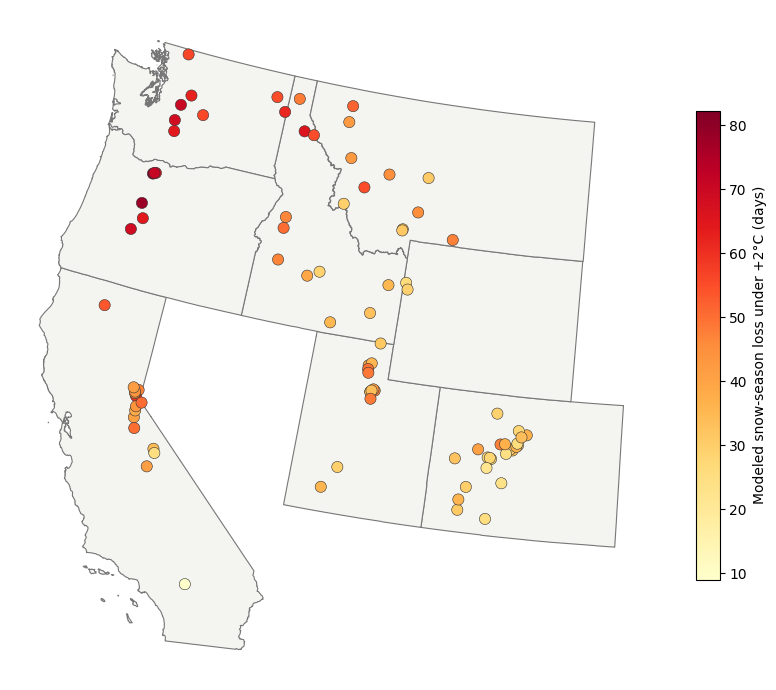

Resorts mapped: 91
Range of modeled losses:
count    91.0
mean     41.9
std      14.3
min       9.0
25%      30.5
50%      40.4
75%      49.8
max      82.3
Name: days_lost_2c, dtype: float64


In [31]:

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

fig_dir = FIG_DIR
fig_dir.mkdir(parents=True, exist_ok=True)

# Join resort coordinates and modeled vulnerability
map_data = resort_states[
    ["resort_id", "resort_name", "geometry"]
].merge(
    resort_vulnerability[
        ["resort_id", "days_lost_2c"]
    ],
    on="resort_id",
    validate="one_to_one"
)

map_data = gpd.GeoDataFrame(
    map_data,
    geometry="geometry",
    crs=resort_states.crs
)

# Use the state boundaries already loaded in the notebook,
# if available. Otherwise retrieve Census state boundaries.
if "states" in globals() and isinstance(states, gpd.GeoDataFrame):
    state_boundaries = states.copy()
else:
    state_boundaries = gpd.read_file(
        "https://www2.census.gov/geo/tiger/GENZ2023/shp/"
        "cb_2023_us_state_500k.zip"
    )

# Restrict to the states represented in the study
study_states = ["CA", "CO", "ID", "MT", "OR", "UT", "WA", "WY"]

if "STUSPS" in state_boundaries.columns:
    state_boundaries = state_boundaries[
        state_boundaries["STUSPS"].isin(study_states)
    ].copy()
elif "state" in state_boundaries.columns:
    state_boundaries = state_boundaries[
        state_boundaries["state"].isin(study_states)
    ].copy()

# Use an equal-area projection for the western U.S.
map_crs = "EPSG:5070"

map_data = map_data.to_crs(map_crs)
state_boundaries = state_boundaries.to_crs(map_crs)

fig, ax = plt.subplots(figsize=(9, 7))

state_boundaries.plot(
    ax=ax,
    facecolor="#F4F4F1",
    edgecolor="#777777",
    linewidth=0.8
)

map_data.plot(
    ax=ax,
    column="days_lost_2c",
    cmap="YlOrRd",
    markersize=65,
    edgecolor="#333333",
    linewidth=0.4,
    legend=True,
    legend_kwds={
        "label": "Modeled snow-season loss under +2°C (days)",
        "shrink": 0.7
    }
)

ax.set_axis_off()
ax.set_aspect("equal")

fig.tight_layout()

fig.savefig(
    fig_dir / "figure_06_resort_vulnerability_map.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    fig_dir / "figure_06_resort_vulnerability_map.pdf",
    bbox_inches="tight"
)

plt.show()

print("Resorts mapped:", len(map_data))
print("Range of modeled losses:")
print(map_data["days_lost_2c"].describe().round(1))


### Figure 6 — Final labels and color scale

*Adapted from original notebook cell 195; retained for methodological traceability.*

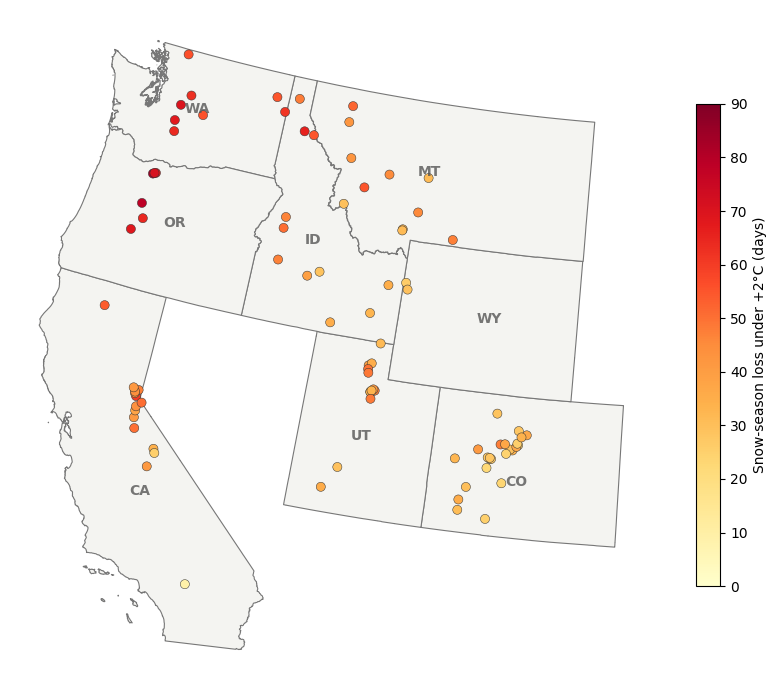

In [32]:

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

fig, ax = plt.subplots(figsize=(9, 7))

# State boundaries
state_boundaries.plot(
    ax=ax,
    facecolor="#F4F4F1",
    edgecolor="#777777",
    linewidth=0.8
)

# Resort vulnerability
map_data.plot(
    ax=ax,
    column="days_lost_2c",
    cmap="YlOrRd",
    norm=mcolors.Normalize(vmin=0, vmax=90),
    markersize=43,
    edgecolor="#333333",
    linewidth=0.35,
    legend=True,
    legend_kwds={
        "label": "Snow-season loss under +2°C (days)",
        "shrink": 0.72
    }
)

# State labels using representative points
state_label_positions = {
    "WA": (-120.7, 47.4),
    "OR": (-120.4, 44.1),
    "CA": (-119.2, 36.5),
    "ID": (-114.9, 44.5),
    "MT": (-110.7, 47.0),
    "WY": (-107.5, 43.1),
    "UT": (-111.7, 39.3),
    "CO": (-105.8, 38.6)
}

# Convert label coordinates to map projection
import geopandas as gpd

label_points = gpd.GeoDataFrame(
    {"state": list(state_label_positions.keys())},
    geometry=gpd.points_from_xy(
        [v[0] for v in state_label_positions.values()],
        [v[1] for v in state_label_positions.values()]
    ),
    crs="EPSG:4326"
).to_crs(map_crs)

for _, row in label_points.iterrows():
    ax.text(
        row.geometry.x,
        row.geometry.y,
        row["state"],
        ha="center",
        va="center",
        fontsize=10,
        fontweight="bold",
        color="#555555",
        alpha=0.8
    )

ax.set_axis_off()
ax.set_aspect("equal")

fig.tight_layout()

fig.savefig(
    fig_dir / "figure_06_resort_vulnerability_map.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    fig_dir / "figure_06_resort_vulnerability_map.pdf",
    bbox_inches="tight"
)

plt.show()


### Figure 1 — Study area

*Adapted from original notebook cell 199; retained for methodological traceability.*

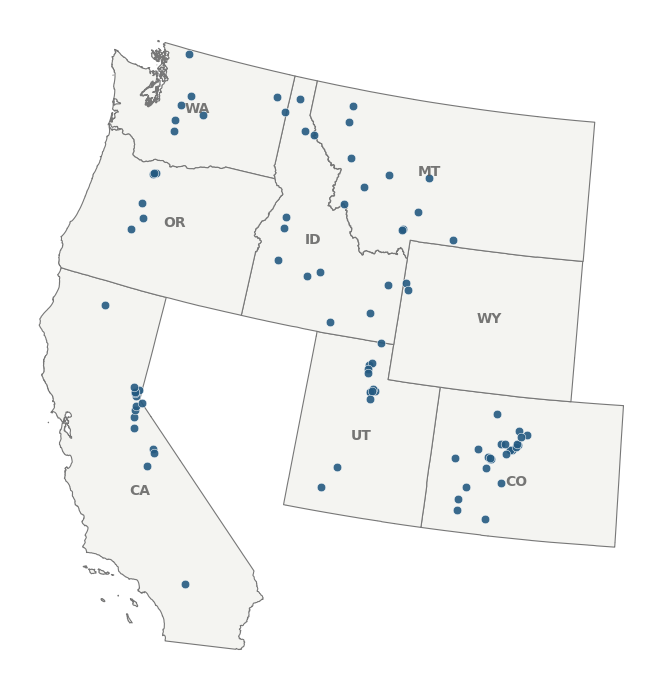

Number of resorts: 91


In [33]:

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 7))

# Western state boundaries
state_boundaries.plot(
    ax=ax,
    facecolor="#F4F4F1",
    edgecolor="#777777",
    linewidth=0.8
)

# All 91 sampled ski resorts
map_data.plot(
    ax=ax,
    color="#245A81",
    markersize=38,
    edgecolor="white",
    linewidth=0.4,
    alpha=0.9
)

# Reuse the state label locations from Figure 6
for _, row in label_points.iterrows():
    ax.text(
        row.geometry.x,
        row.geometry.y,
        row["state"],
        ha="center",
        va="center",
        fontsize=10,
        fontweight="bold",
        color="#555555",
        alpha=0.8
    )

ax.set_axis_off()
ax.set_aspect("equal")

fig.tight_layout()

fig.savefig(
    fig_dir / "figure_01_study_area.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    fig_dir / "figure_01_study_area.pdf",
    bbox_inches="tight"
)

plt.show()

print("Number of resorts:", len(map_data))


### Figure 2 — Independent test daily-depth validation

*Adapted from original notebook cell 198; retained for methodological traceability.*

INDEPENDENT TEST PERFORMANCE
Observations: 74,529
MAE: 0.157 m
RMSE: 0.268 m
R²: 0.884


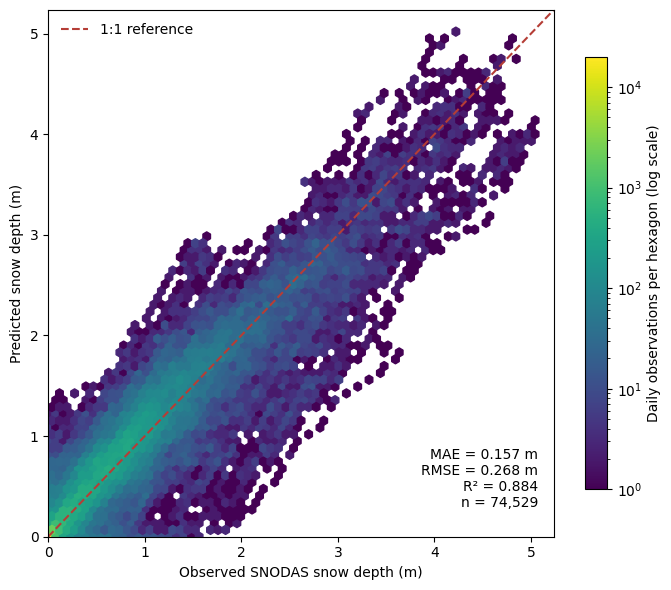

In [34]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

fig_dir = FIG_DIR
fig_dir.mkdir(parents=True, exist_ok=True)

# Independent test-period recursive predictions
plot_df = recursive_test.loc[
    recursive_test["winter_year"].between(2021, 2023),
    ["snow_depth_m", "recursive_pred_m"]
].dropna().copy()

observed = plot_df["snow_depth_m"].to_numpy()
predicted = plot_df["recursive_pred_m"].to_numpy()

mae = mean_absolute_error(observed, predicted)
rmse = np.sqrt(mean_squared_error(observed, predicted))
r2 = r2_score(observed, predicted)

print("INDEPENDENT TEST PERFORMANCE")
print(f"Observations: {len(plot_df):,}")
print(f"MAE: {mae:.3f} m")
print(f"RMSE: {rmse:.3f} m")
print(f"R²: {r2:.3f}")

# Consistent axes for observed and predicted depth
axis_max = max(observed.max(), predicted.max()) * 1.03

fig, ax = plt.subplots(figsize=(7, 6))

hb = ax.hexbin(
    observed,
    predicted,
    gridsize=65,
    cmap="viridis",
    mincnt=1,
    bins="log"
)

ax.plot(
    [0, axis_max],
    [0, axis_max],
    linestyle="--",
    color="#B53D36",
    linewidth=1.5,
    label="1:1 reference"
)

ax.set_xlim(0, axis_max)
ax.set_ylim(0, axis_max)

ax.set_xlabel("Observed SNODAS snow depth (m)")
ax.set_ylabel("Predicted snow depth (m)")

ax.legend(frameon=False, loc="upper left")

ax.text(
    0.97, 0.05,
    f"MAE = {mae:.3f} m\n"
    f"RMSE = {rmse:.3f} m\n"
    f"R² = {r2:.3f}\n"
    f"n = {len(plot_df):,}",
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=10,
    bbox=dict(
        facecolor="white",
        edgecolor="none",
        alpha=0.85
    )
)

cbar = fig.colorbar(hb, ax=ax, shrink=0.82)
cbar.set_label("Daily observations per hexagon (log scale)")

fig.tight_layout()

fig.savefig(
    fig_dir / "figure_02_recursive_model_validation.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    fig_dir / "figure_02_recursive_model_validation.pdf",
    bbox_inches="tight"
)

plt.show()


### Figure 3 — Warming sensitivity with bootstrap intervals

*Adapted from original notebook cell 191; retained for methodological traceability.*

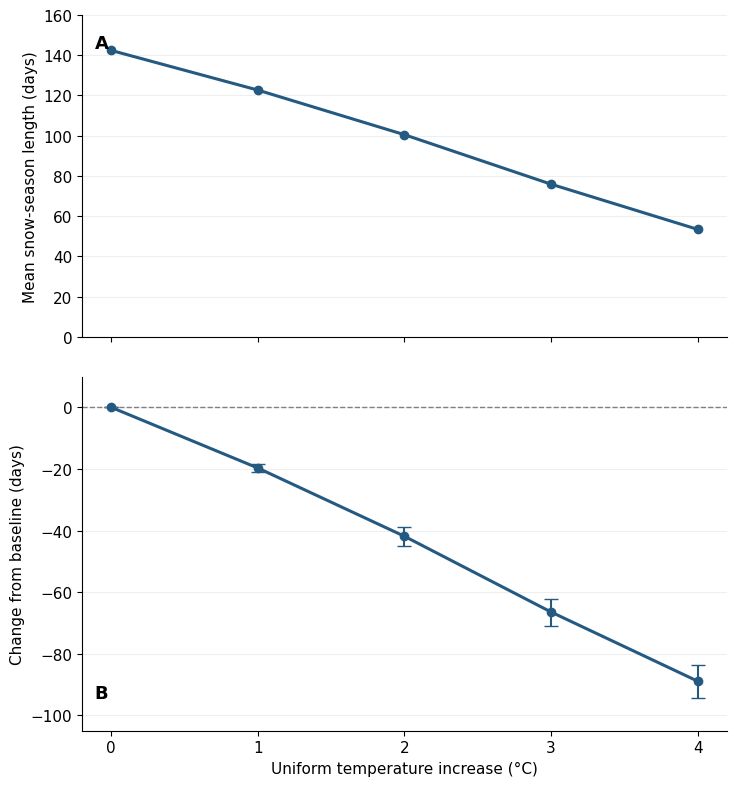

Saved final Figure 3:
/Users/evabenson/Files/thesis/ski_thesis_clean/outputs/thesis_figures/figure_03_warming_sensitivity.png
/Users/evabenson/Files/thesis/ski_thesis_clean/outputs/thesis_figures/figure_03_warming_sensitivity.pdf


In [35]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

fig_dir = FIG_DIR
fig_dir.mkdir(parents=True, exist_ok=True)

# Mean modeled season length
means = (
    climate_results
    .groupby("warming_c", as_index=False)
    .agg(mean_days=("season_days", "mean"))
    .sort_values("warming_c")
)

# Bootstrap uncertainty for changes from baseline
ci = warming_uncertainty.sort_values("warming_c").copy()

# Include baseline (zero change by definition)
ci = pd.concat([
    pd.DataFrame({
        "warming_c": [0],
        "mean_change_days": [0.0],
        "ci_lower": [0.0],
        "ci_upper": [0.0]
    }),
    ci
], ignore_index=True)

# Asymmetric confidence interval distances
lower_err = ci["mean_change_days"] - ci["ci_lower"]
upper_err = ci["ci_upper"] - ci["mean_change_days"]

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "pdf.fonttype": 42,
    "savefig.dpi": 300
})

fig, (ax1, ax2) = plt.subplots(
    2, 1,
    figsize=(7.5, 8),
    sharex=True,
    gridspec_kw={"height_ratios": [1, 1.1]}
)

color = "#245A81"

# Panel A: Absolute season length
ax1.plot(
    means["warming_c"],
    means["mean_days"],
    color=color,
    marker="o",
    linewidth=2.2,
    markersize=6
)

ax1.set_ylabel("Mean snow-season length (days)")
ax1.set_ylim(0, 160)
ax1.grid(axis="y", alpha=0.2)
ax1.text(
    0.02, 0.94, "A",
    transform=ax1.transAxes,
    fontsize=13, fontweight="bold",
    va="top"
)

# Panel B: Changes relative to baseline
ax2.errorbar(
    ci["warming_c"],
    ci["mean_change_days"],
    yerr=np.vstack([lower_err, upper_err]),
    fmt="o-",
    color=color,
    linewidth=2.2,
    markersize=6,
    capsize=5,
    elinewidth=1.5
)

ax2.axhline(0, color="gray", linewidth=1, linestyle="--")
ax2.set_ylabel("Change from baseline (days)")
ax2.set_xlabel("Uniform temperature increase (°C)")
ax2.set_xticks([0, 1, 2, 3, 4])
ax2.set_ylim(-105, 10)
ax2.grid(axis="y", alpha=0.2)
ax2.text(
    0.02, 0.08, "B",
    transform=ax2.transAxes,
    fontsize=13, fontweight="bold",
    va="bottom"
)

fig.tight_layout(h_pad=2)

fig.savefig(
    fig_dir / "figure_03_warming_sensitivity.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    fig_dir / "figure_03_warming_sensitivity.pdf",
    bbox_inches="tight"
)

plt.show()

print("Saved final Figure 3:")
print(fig_dir / "figure_03_warming_sensitivity.png")
print(fig_dir / "figure_03_warming_sensitivity.pdf")


### Figure 4 — Elevation quartile response

*Adapted from original notebook cell 192; retained for methodological traceability.*

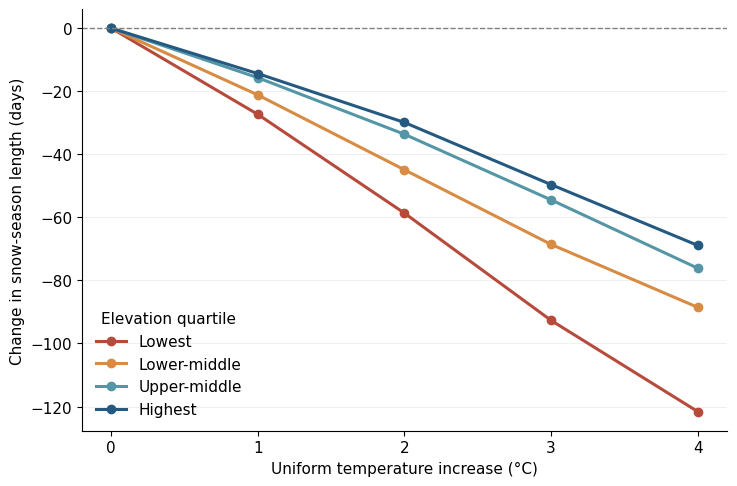


+2°C ELEVATION RESULTS


,elevation_quartile,baseline_days,mean_season_days,change_days
2,Lowest,154.9,96.2,-58.7
7,Lower-middle,126.2,81.3,-44.9
12,Upper-middle,137.6,103.9,-33.6
17,Highest,150.6,120.7,-29.9



Saved Figure 4 to: /Users/evabenson/Files/thesis/ski_thesis_clean/outputs/thesis_figures


In [36]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

fig_dir = FIG_DIR
fig_dir.mkdir(parents=True, exist_ok=True)

# Resort elevations (one record per resort)
elevations = (
    resort_info[["resort_id", "elevation_m"]]
    .drop_duplicates("resort_id")
    .copy()
)

elevations["elevation_quartile"] = pd.qcut(
    elevations["elevation_m"],
    q=4,
    labels=[
        "Lowest",
        "Lower-middle",
        "Upper-middle",
        "Highest"
    ]
)

# Join elevation quartiles to climate scenario results
elevation_climate = climate_results.merge(
    elevations[["resort_id", "elevation_quartile"]],
    on="resort_id",
    validate="many_to_one"
)

# Average season length by elevation and warming scenario
elevation_summary = (
    elevation_climate.groupby(
        ["elevation_quartile", "warming_c"],
        observed=True
    )
    .agg(mean_season_days=("season_days", "mean"))
    .reset_index()
)

# Calculate changes relative to each elevation group's baseline
baseline = (
    elevation_summary[
        elevation_summary["warming_c"] == 0
    ][["elevation_quartile", "mean_season_days"]]
    .rename(columns={
        "mean_season_days": "baseline_days"
    })
)

elevation_summary = elevation_summary.merge(
    baseline,
    on="elevation_quartile",
    validate="many_to_one"
)

elevation_summary["change_days"] = (
    elevation_summary["mean_season_days"]
    - elevation_summary["baseline_days"]
)

# Plot
fig, ax = plt.subplots(figsize=(7.5, 5))

colors = {
    "Lowest": "#B64B3C",
    "Lower-middle": "#D88B42",
    "Upper-middle": "#5496A5",
    "Highest": "#245A81"
}

for group in colors:
    subset = elevation_summary[
        elevation_summary["elevation_quartile"] == group
    ].sort_values("warming_c")

    ax.plot(
        subset["warming_c"],
        subset["change_days"],
        marker="o",
        linewidth=2.2,
        markersize=6,
        color=colors[group],
        label=group
    )

ax.axhline(0, color="gray", linewidth=1, linestyle="--")

ax.set(
    xlabel="Uniform temperature increase (°C)",
    ylabel="Change in snow-season length (days)",
    xticks=[0, 1, 2, 3, 4]
)

ax.grid(axis="y", alpha=0.2)
ax.legend(title="Elevation quartile", frameon=False)

fig.tight_layout()

fig.savefig(
    fig_dir / "figure_04_elevation_vulnerability.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    fig_dir / "figure_04_elevation_vulnerability.pdf",
    bbox_inches="tight"
)

plt.show()

print("\n+2°C ELEVATION RESULTS")
display(
    elevation_summary[
        elevation_summary["warming_c"] == 2
    ][
        ["elevation_quartile", "baseline_days",
         "mean_season_days", "change_days"]
    ].round(1)
)

print("\nSaved Figure 4 to:", fig_dir.resolve())


### Figure 5 — State vulnerability

*Adapted from original notebook cell 193; retained for methodological traceability.*

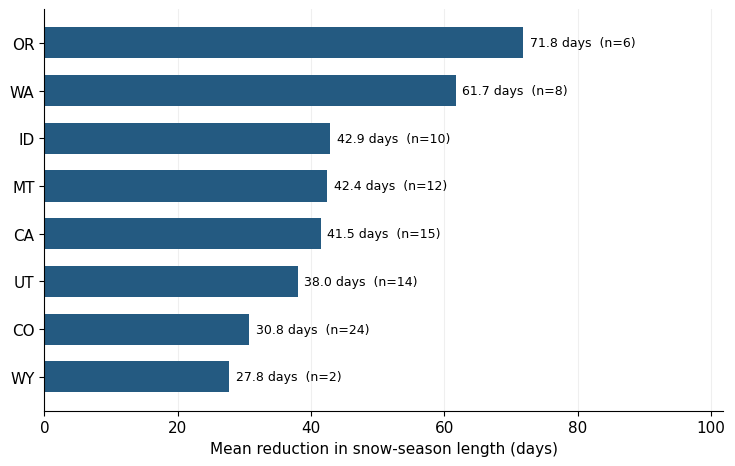


STATE VULNERABILITY SUMMARY


,state,n_resorts,mean_loss_days
4,OR,6,71.8
6,WA,8,61.7
2,ID,10,42.9
3,MT,12,42.4
0,CA,15,41.5
5,UT,14,38.0
1,CO,24,30.8
7,WY,2,27.8


In [37]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

fig_dir = FIG_DIR
fig_dir.mkdir(parents=True, exist_ok=True)

# Use resort-level losses to calculate state means
state_fig = (
    resort_vulnerability
    .groupby("state", as_index=False)
    .agg(
        n_resorts=("resort_id", "nunique"),
        mean_loss_days=("days_lost_2c", "mean")
    )
    .sort_values("mean_loss_days", ascending=True)
)

fig, ax = plt.subplots(figsize=(7.5, 4.8))

bars = ax.barh(
    state_fig["state"],
    state_fig["mean_loss_days"],
    color="#245A81",
    height=0.65
)

# Label each bar with loss and sample size
for bar, (_, row) in zip(bars, state_fig.iterrows()):
    ax.text(
        bar.get_width() + 1,
        bar.get_y() + bar.get_height() / 2,
        f'{row["mean_loss_days"]:.1f} days  (n={int(row["n_resorts"])})',
        va="center",
        fontsize=9
    )

ax.set_xlabel("Mean reduction in snow-season length (days)")
ax.set_ylabel("")
ax.set_xlim(0, state_fig["mean_loss_days"].max() + 30)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

fig.tight_layout()

fig.savefig(
    fig_dir / "figure_05_state_vulnerability.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    fig_dir / "figure_05_state_vulnerability.pdf",
    bbox_inches="tight"
)

plt.show()

print("\nSTATE VULNERABILITY SUMMARY")
display(
    state_fig.sort_values(
        "mean_loss_days", ascending=False
    ).round(1)
)


## 7. Thesis tables

Tables are exported to `outputs/thesis_tables/`. **Interpretation note:** The daily-depth training accuracy is not an out-of-sample result; season-length results include historical simulations. The 20-day MAE filter is a diagnostic cutoff, not a formal statistical threshold.

### Table 1 — Sample coverage and descriptive statistics

*Adapted from original notebook cell 200; retained for methodological traceability.*

In [38]:

import pandas as pd
from pathlib import Path

table_dir = TABLE_DIR
table_dir.mkdir(parents=True, exist_ok=True)

# Resort sample by state
state_sample = (
    resort_info.groupby("state")
    .agg(n_resorts=("resort_id", "nunique"))
    .reset_index()
    .sort_values("n_resorts", ascending=False)
)

print("TABLE 1A: RESORT SAMPLE BY STATE")
display(state_sample)

# Descriptive statistics
variables = {
    "snow_depth_m": "SNODAS snow depth (m)",
    "tmin": "Daily minimum temperature (°C)",
    "tmax": "Daily maximum temperature (°C)",
    "prcp": "Daily precipitation (mm)",
    "elevation_m": "Resort elevation (m)"
}

summary_rows = []

for col, label in variables.items():
    if col == "elevation_m":
        values = resort_info[col].dropna()
    else:
        values = recursive_df[col].dropna()

    summary_rows.append({
        "Variable": label,
        "N": len(values),
        "Mean": values.mean(),
        "SD": values.std(),
        "Min": values.min(),
        "Max": values.max()
    })

descriptive_table = pd.DataFrame(summary_rows)

print("\nTABLE 1B: DESCRIPTIVE STATISTICS")
display(descriptive_table.round(2))

state_sample.to_csv(
    table_dir / "table_01_state_sample.csv",
    index=False
)

descriptive_table.to_csv(
    table_dir / "table_01_descriptive_statistics.csv",
    index=False
)

print("\nTables saved to:", table_dir.resolve())


TABLE 1A: RESORT SAMPLE BY STATE


,state,n_resorts
1,CO,24
0,CA,15
5,UT,14
3,MT,12
2,ID,10
6,WA,8
4,OR,6
7,WY,2



TABLE 1B: DESCRIPTIVE STATISTICS


,Variable,N,Mean,SD,Min,Max
0,SNODAS snow depth (m),496405,0.62,0.78,0.00,6.22
1,Daily minimum temperature (°C),497315,-3.51,6.82,-38.65,22.34
2,Daily maximum temperature (°C),497315,7.64,8.08,-27.08,39.78
3,Daily precipitation (mm),497315,3.24,7.33,0.00,197.91
4,Resort elevation (m),91,2202.77,576.71,945.49,3432.96



Tables saved to: /Users/evabenson/Files/thesis/ski_thesis_clean/outputs/thesis_tables


### Table 2 — Model performance and zero-season recall

*Adapted from original notebook cell 201; retained for methodological traceability.*

In [39]:

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from pathlib import Path

table_dir = TABLE_DIR
table_dir.mkdir(parents=True, exist_ok=True)

# Daily recursive predictions available for validation and test
daily_sources = {
    "Validation (2018–2020)": recursive_predictions,
    "Test (2021–2023)": recursive_test
}

rows = []

for period, data in daily_sources.items():
    years = (2018, 2020) if "Validation" in period else (2021, 2023)

    subset = data.loc[
        data["winter_year"].between(*years),
        ["snow_depth_m", "recursive_pred_m"]
    ].dropna()

    obs = subset["snow_depth_m"].to_numpy()
    pred = subset["recursive_pred_m"].to_numpy()

    rows.append({
        "Outcome": "Daily snow depth",
        "Period": period,
        "N": len(subset),
        "MAE": mean_absolute_error(obs, pred),
        "RMSE": np.sqrt(mean_squared_error(obs, pred)),
        "R²": r2_score(obs, pred),
        "Bias": np.mean(pred - obs),
        "Units": "meters"
    })

# Season-length performance for all three periods
for period, years in [
    ("Training (2004–2017)", (2004, 2017)),
    ("Validation (2018–2020)", (2018, 2020)),
    ("Test (2021–2023)", (2021, 2023))
]:
    subset = full_validation.loc[
        full_validation["winter_year"].between(*years)
    ]

    obs = subset["observed_days"].to_numpy()
    pred = subset["predicted_days"].to_numpy()

    rows.append({
        "Outcome": "Snow-season length",
        "Period": period,
        "N": len(subset),
        "MAE": mean_absolute_error(obs, pred),
        "RMSE": np.sqrt(mean_squared_error(obs, pred)),
        "R²": r2_score(obs, pred),
        "Bias": np.mean(pred - obs),
        "Units": "days"
    })

performance_table = pd.DataFrame(rows)

print("TABLE 2: MODEL PERFORMANCE")
display(performance_table.round(3))

# Zero-season classification
zero_rows = []

for period, years in [
    ("Training", (2004, 2017)),
    ("Validation", (2018, 2020)),
    ("Test", (2021, 2023))
]:
    subset = full_validation.loc[
        full_validation["winter_year"].between(*years)
    ]

    observed_zero = subset["observed_days"] == 0
    predicted_zero = subset["predicted_days"] == 0

    tp = (observed_zero & predicted_zero).sum()

    zero_rows.append({
        "Period": period,
        "Observed zero seasons": observed_zero.sum(),
        "Predicted zero seasons": predicted_zero.sum(),
        "Recall": tp / observed_zero.sum()
        if observed_zero.sum() else np.nan
    })

zero_performance = pd.DataFrame(zero_rows)

print("\nZERO-SEASON CLASSIFICATION")
display(zero_performance.round(3))

performance_table.to_csv(
    table_dir / "table_02_model_performance.csv",
    index=False
)

zero_performance.to_csv(
    table_dir / "table_02_zero_season_performance.csv",
    index=False
)


TABLE 2: MODEL PERFORMANCE


,Outcome,Period,N,MAE,RMSE,R²,Bias,Units
0,Daily snow depth,Validation (2018–2020),74620,0.154,0.275,0.844,0.023,meters
1,Daily snow depth,Test (2021–2023),74529,0.157,0.268,0.884,0.017,meters
2,Snow-season length,Training (2004–2017),1274,18.753,28.520,0.753,4.002,days
3,Snow-season length,Validation (2018–2020),273,21.498,28.689,0.731,5.901,days
4,Snow-season length,Test (2021–2023),273,18.381,27.148,0.722,4.300,days



ZERO-SEASON CLASSIFICATION


,Period,Observed zero seasons,Predicted zero seasons,Recall
0,Training,61,29,0.410
1,Validation,13,2,0.154
2,Test,6,2,0.333


### Table 3 — Warming scenario results

*Adapted from original notebook cell 202; retained for methodological traceability.*

In [40]:

import numpy as np
import pandas as pd
from pathlib import Path

table_dir = TABLE_DIR
table_dir.mkdir(parents=True, exist_ok=True)

# Summarize each warming scenario
scenario_table = (
    climate_results.groupby("warming_c", as_index=False)
    .agg(
        resort_winters=("season_days", "size"),
        mean_season_days=("season_days", "mean"),
        median_season_days=("season_days", "median"),
        zero_season_winters=("season_days", lambda x: (x == 0).sum())
    )
    .sort_values("warming_c")
)

# Changes relative to the modeled historical baseline
baseline_mean = scenario_table.loc[
    scenario_table["warming_c"] == 0,
    "mean_season_days"
].iloc[0]

scenario_table["change_days"] = (
    scenario_table["mean_season_days"] - baseline_mean
)

scenario_table["pct_change"] = (
    100 * scenario_table["change_days"] / baseline_mean
)

scenario_table["zero_season_pct"] = (
    100 * scenario_table["zero_season_winters"]
    / scenario_table["resort_winters"]
)

# Join existing resort-cluster bootstrap confidence intervals
scenario_table = scenario_table.merge(
    warming_uncertainty[
        ["warming_c", "ci_lower", "ci_upper"]
    ],
    on="warming_c",
    how="left",
    validate="one_to_one"
)

# Baseline change is zero by definition
scenario_table.loc[
    scenario_table["warming_c"] == 0,
    ["ci_lower", "ci_upper"]
] = 0.0

# Formatted version for the thesis
thesis_table_3 = pd.DataFrame({
    "Warming (°C)": scenario_table["warming_c"],
    "Mean season (days)": scenario_table["mean_season_days"].round(1),
    "Change (days)": scenario_table["change_days"].round(1),
    "Change (%)": scenario_table["pct_change"].round(1),
    "95% CI for change (days)": [
        "Reference" if w == 0 else f"[{lo:.1f}, {hi:.1f}]"
        for w, lo, hi in zip(
            scenario_table["warming_c"],
            scenario_table["ci_lower"],
            scenario_table["ci_upper"]
        )
    ],
    "Zero-season winters": scenario_table["zero_season_winters"],
    "Zero-season share (%)": scenario_table["zero_season_pct"].round(1)
})

print("TABLE 3: WARMING SCENARIO RESULTS")
display(thesis_table_3)

thesis_table_3.to_csv(
    table_dir / "table_03_warming_scenarios.csv",
    index=False
)

scenario_table.to_csv(
    table_dir / "table_03_warming_scenarios_unrounded.csv",
    index=False
)

print("\nSaved to:", table_dir.resolve())


TABLE 3: WARMING SCENARIO RESULTS


,Warming (°C),Mean season (days),Change (days),Change (%),95% CI for change (days),Zero-season winters,Zero-season share (%)
0,0,142.4,0.0,0.0,Reference,33,1.8
1,1,122.7,-19.7,-13.8,"[-21.1, -18.3]",74,4.1
2,2,100.5,-41.9,-29.4,"[-44.9, -38.9]",160,8.8
3,3,75.9,-66.5,-46.7,"[-70.9, -62.1]",305,16.8
4,4,53.5,-88.9,-62.4,"[-94.5, -83.5]",524,28.8



Saved to: /Users/evabenson/Files/thesis/ski_thesis_clean/outputs/thesis_tables


### Table 4 — State vulnerability and robustness

*Adapted from original notebook cell 203; retained for methodological traceability.*

In [41]:

import pandas as pd
from pathlib import Path

table_dir = TABLE_DIR
table_dir.mkdir(parents=True, exist_ok=True)

# State-level results from the full sample
state_summary = (
    resort_vulnerability.groupby("state", as_index=False)
    .agg(
        n_resorts=("resort_id", "nunique"),
        baseline_days=("baseline_days", "mean"),
        warming_2c_days=("warming_2c_days", "mean"),
        days_lost=("days_lost_2c", "mean"),
        pct_lost=("pct_season_lost_2c", "mean")
    )
)

# Accuracy-filtered robustness results
robustness_summary = (
    vulnerability_accuracy.assign(
        retained=lambda x: x["test_mae_days"] <= 20
    )
    .groupby("state")
    .apply(
        lambda g: pd.Series({
            "retained_resorts": int(g["retained"].sum()),
            "filtered_loss": g.loc[
                g["retained"], "days_lost_2c"
            ].mean()
        }),
        include_groups=False
    )
    .reset_index()
)

# Combine
state_table = state_summary.merge(
    robustness_summary,
    on="state",
    validate="one_to_one"
).sort_values("days_lost", ascending=False)

# Use the ratio of state means for percentage loss,
# rather than averaging individual resort percentages.
state_table["pct_lost"] = (
    100 * state_table["days_lost"]
    / state_table["baseline_days"]
)

thesis_table_4 = pd.DataFrame({
    "State": state_table["state"],
    "Resorts": state_table["n_resorts"],
    "Baseline (days)": state_table["baseline_days"].round(1),
    "+2°C (days)": state_table["warming_2c_days"].round(1),
    "Loss (days)": state_table["days_lost"].round(1),
    "Loss (%)": state_table["pct_lost"].round(1),
    "Retained (MAE ≤20d)": state_table["retained_resorts"].astype(int),
    "Filtered loss (days)": state_table["filtered_loss"].round(1)
})

print("TABLE 4: STATE VULNERABILITY AND ROBUSTNESS")
display(thesis_table_4)

thesis_table_4.to_csv(
    table_dir / "table_04_state_vulnerability.csv",
    index=False
)

state_table.to_csv(
    table_dir / "table_04_state_vulnerability_unrounded.csv",
    index=False
)

print("\nSaved to:", table_dir.resolve())


TABLE 4: STATE VULNERABILITY AND ROBUSTNESS


,State,Resorts,Baseline (days),+2°C (days),Loss (days),Loss (%),Retained (MAE ≤20d),Filtered loss (days)
4,OR,6,166.0,94.2,71.8,43.3,3,71.1
6,WA,8,176.1,114.4,61.7,35.1,8,61.7
2,ID,10,131.8,88.9,42.9,32.5,8,45.1
3,MT,12,147.5,105.0,42.4,28.8,6,42.9
0,CA,15,119.9,78.4,41.5,34.6,9,38.7
5,UT,14,142.8,104.8,38.0,26.6,9,38.1
1,CO,24,138.8,108.0,30.8,22.2,18,30.4
7,WY,2,168.6,140.8,27.8,16.5,1,26.3



Saved to: /Users/evabenson/Files/thesis/ski_thesis_clean/outputs/thesis_tables


## 8. Final integrity checks and export manifest

The assertions below detect incomplete reruns, missing resort coverage, and accidentally mixed model outputs. The legacy `outputs/model_validation_predictions.csv` belongs to an earlier county-level fixed-effects experiment and is **not** used in the thesis.

In [42]:
assert climate_results["resort_id"].nunique() == 91
assert climate_results["winter_year"].nunique() == 20
assert set(climate_results["warming_c"]) == {0, 1, 2, 3, 4}
assert len(climate_results) == 91 * 20 * 5
assert len(full_validation) == 91 * 20
assert recursive_test["winter_year"].between(2021, 2023).all()
assert len(resort_vulnerability) == 91
assert len(state_vulnerability) == 8
print("Integrity checks passed.")
print("Figures:", sorted(p.name for p in FIG_DIR.glob("*.pdf")))
print("Tables:", sorted(p.name for p in TABLE_DIR.glob("*.csv")))


Integrity checks passed.
Figures: ['figure_01_study_area.pdf', 'figure_02_recursive_model_validation.pdf', 'figure_03_warming_response.pdf', 'figure_03_warming_sensitivity.pdf', 'figure_04_elevation_vulnerability.pdf', 'figure_05_state_vulnerability.pdf', 'figure_06_resort_vulnerability_map.pdf']
Tables: ['table_01_descriptive_statistics.csv', 'table_01_state_sample.csv', 'table_02_model_performance.csv', 'table_02_zero_season_performance.csv', 'table_03_warming_scenarios.csv', 'table_03_warming_scenarios_unrounded.csv', 'table_04_state_vulnerability.csv', 'table_04_state_vulnerability_unrounded.csv']
